# TNF binder prediction with ESMC: a research notebook and PyTorch tutorial

**Question:** Does LoRA adaptation improve experimental binder enrichment, and does an extreme presumed-negative pool help?

This notebook contains the actual data-curation, generation, fine-tuning, cross-validation, and evaluation code used in the run, followed by the recorded results. Tutorial examples execute on the CPU; full model generation/training belongs in an explicit Slurm GPU allocation.

The target is **human TNF-alpha**. A sequence classifier trained on this task is not a general binder detector, an affinity predictor, or a mouse/pH classifier. The only experimental labels are from the published dataset. Generated decoys are **unassayed presumed negatives**, not measured hard negatives.

**Read in order:** PyTorch tensors and autograd → data/splits → masked-language-model decoys → LoRA → training → held-out evidence.

## 1. Tensors, shapes, devices, and gradients
A tensor is an array with a dtype and a device. `requires_grad=True` asks PyTorch to track operations so it can differentiate a loss. `.backward()` accumulates gradients; an optimizer changes parameters; `zero_grad()` prevents gradients from unintentionally accumulating between independent steps.

For proteins, token IDs have shape `[batch, length]`; ESMC representations have shape `[batch, length, channels]`; a binary head returns **one logit per sequence**.

In [1]:
%matplotlib inline
import torch
from torch import nn
from torch.nn import functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
torch.manual_seed(42)
x = torch.tensor([[0.2, 0.8], [0.9, 0.1]], dtype=torch.float32)
y = torch.tensor([1.0, 0.0])
head = nn.Linear(2, 1)  # weight and bias are trainable Parameters.
optimizer = torch.optim.AdamW(head.parameters(), lr=0.05)
losses = []
for step in range(30):
    optimizer.zero_grad(set_to_none=True)
    logits = head(x).squeeze(-1)
    loss = F.binary_cross_entropy_with_logits(logits, y)
    loss.backward()
    if step == 0:
        print('input:', x.shape, x.dtype, x.device)
        print('weight gradient:', head.weight.grad)
    optimizer.step()
    losses.append(loss.item())
print('Toy training loss:', losses[0], '->', losses[-1])
print('Toy probabilities:', head(x).sigmoid().detach().flatten().tolist())
assert losses[-1] < losses[0]

input: torch.Size([2, 2]) torch.float32 cpu
weight gradient: tensor([[ 0.2274, -0.1297]])
Toy training loss: 0.7045317888259888 -> 0.3228745460510254
Toy probabilities: [0.7379437685012817, 0.27826833724975586]


### Logits, probabilities, and the meaning of 0.1%
`sigmoid(logit)` maps a score into (0, 1), but a sigmoid output is not automatically calibrated. `binary_cross_entropy_with_logits` combines sigmoid and binary cross entropy stably.

**Positive prevalence** is P/(P+N). **True-positive rate / recall** is TP/(TP+FN). They are different quantities. A 0.1%-positive pool has about 999 negatives per positive. An always-negative classifier then has 99.9% accuracy and zero recall. The study therefore measures average precision and top-decile enrichment, not accuracy.

The synthetic arm constructs a 0.1%-positive training reservoir but draws balanced, confidence-weighted minibatches. It does **not** claim that extreme imbalance itself forces generalization.

In [2]:
positive_fraction = 0.001
print('Always-negative accuracy:', 1-positive_fraction)
print('Always-negative recall:', 0.0)
from torch.utils.data import TensorDataset, DataLoader
toy_dataset = TensorDataset(x, y)
loader = DataLoader(toy_dataset, batch_size=2, shuffle=True,
                    generator=torch.Generator().manual_seed(42))
for xb, yb in loader:
    print('DataLoader batch:', xb.shape, yb.shape)

Always-negative accuracy: 0.999
Always-negative recall: 0.0
DataLoader batch: torch.Size([2, 2]) torch.Size([2])


## Imports and reproducibility

The following cells are the exact implementation, not pseudocode. RNG seeds, source hashes, configuration, and split identities are retained. Random seeds make the stochastic protocol repeatable, but CUDA kernels and environment versions can still affect numerical results.

In [3]:
from __future__ import annotations
import argparse, copy, gc, hashlib, json, math, os, random, time
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, log_loss
from esm.models.esmc import EsmcForMaskedLM, EsmcTokenizer

AA = "ACDEFGHIKLMNPQRSTVWY"
DEFAULTS = dict(seed=42, model="biohub/ESMC-300M", folds=3, epochs=8,
                steps_per_epoch=16, batch_size=8, rank=8, alpha=16,
                lora_lr=1e-4, head_lr=3e-4, weight_decay=0.01,
                dropout=0.1, generated_count=12000, generation_batch=32,
                generation_rounds=2, mask_fraction=0.35, temperature=1.0,
                pool_positive_fraction=0.001, synthetic_loss_weight=0.25,
                donor_targets=["EGFR", "RBX1", "TrkA", "15-PGDH"],
                arms=["lora_assay_only", "lora_presumed_negative_pool"])

def seed_everything(seed: int) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def write_json(path: Path, value) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(path.suffix + ".tmp")
    temp.write_text(json.dumps(value, indent=2, allow_nan=False, default=str) + "\n")
    temp.replace(path)

def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024*1024), b""): h.update(chunk)
    return h.hexdigest()

def truth(series: pd.Series) -> pd.Series:
    return series.astype(str).str.lower().eq("true")

def require_slurm_gpu() -> None:
    if not os.environ.get("SLURM_JOB_ID"):
        raise RuntimeError("GPU work must be submitted with sbatch, not run on the laptop.")
    if not torch.cuda.is_available(): raise RuntimeError("Slurm job has no CUDA device.")
    if "3060" not in torch.cuda.get_device_name(0):
        raise RuntimeError("This registered study is restricted to the RTX 3060.")
    torch.set_num_threads(4)
    torch.set_float32_matmul_precision("high")
    torch.cuda.set_per_process_memory_fraction(0.85)

## Data curation and the locked 70/15/15 split

The source is filtered to TNF-alpha. Adjudicated positives are retained; negatives must have an explicit expressed nonbinder call. Missing assays and non-expression are not relabeled as binding failures. Exact duplicate sequences are removed before splitting; contradictory duplicates are excluded. The 15% test set is untouched by cross-validation.

In [4]:
def prepare_data(root: Path, cfg: dict):
    raw_path = root / "input/design_summary.csv"
    raw = pd.read_csv(raw_path)
    raw["sequence"] = raw.sequence.str.upper().str.strip()
    tnf = raw.loc[raw.target.eq("TNFa")].copy()
    final_positive = truth(tnf.binder_final)
    # Do not turn non-expression or missing assays into binding negatives.
    qualified_negative = (~final_positive & tnf.adaptyv_binding.eq("non_binder")
                          & tnf.adaptyv_expression.isin(["medium", "high", "low"]))
    eligible = final_positive | qualified_negative
    excluded = tnf.loc[~eligible, ["uuid", "adaptyv_binding", "adaptyv_expression"]]
    real = tnf.loc[eligible].copy()
    real["label"] = truth(real.binder_final).astype(int)
    real["label_source"] = "adjudicated binder_final; expressed-negative QC"
    real["label_status"] = "experimental"
    assert real.sequence.map(lambda s: 1 <= len(s) <= 512 and set(s) <= set(AA)).all()
    conflicts = real.groupby("sequence").label.nunique()
    conflict_sequences = set(conflicts[conflicts > 1].index)
    real = real.loc[~real.sequence.isin(conflict_sequences)].sort_values("uuid")
    before_dedup = len(real)
    real = real.drop_duplicates("sequence").reset_index(drop=True)
    ids = np.arange(len(real)); y = real.label.to_numpy()
    train, remainder = train_test_split(ids, test_size=0.30, random_state=cfg["seed"], stratify=y)
    val, test = train_test_split(remainder, test_size=0.50, random_state=cfg["seed"], stratify=y[remainder])
    split = {"train": sorted(train.tolist()), "validation": sorted(val.tolist()), "test": sorted(test.tolist())}
    assert not (set(train)&set(val) or set(train)&set(test) or set(val)&set(test))
    assert set(train)|set(val)|set(test) == set(ids)
    real["split"] = "train"
    real.loc[val, "split"] = "validation"; real.loc[test, "split"] = "test"
    donors = raw.loc[raw.target.isin(cfg["donor_targets"]) & truth(raw.binder_final)].copy()
    donors = donors.loc[~donors.sequence.isin(set(real.sequence))].drop_duplicates("sequence")
    donors = donors.sort_values(["target", "uuid"]).reset_index(drop=True)
    assert len(donors) > 0
    (root / "data").mkdir(exist_ok=True)
    real.to_csv(root / "data/experimental.csv", index=False)
    donors.to_csv(root / "data/donors.csv", index=False)
    excluded.to_csv(root / "data/excluded.csv", index=False)
    audit = dict(source_url="https://huggingface.co/datasets/Anthropic/claude-protein-binder-design",
                 source_file="data/tables/design_summary.parquet", local_csv_sha256=sha256(raw_path),
                 source_target_rows=len(tnf), eligible=len(real), positives=int(y.sum()),
                 negatives=int((y==0).sum()), excluded_assay_qc=len(excluded),
                 conflicting_sequences=len(conflict_sequences), exact_duplicates_removed=before_dedup-len(real),
                 donor_counts=donors.target.value_counts().to_dict(),
                 split_counts={k: dict(n=len(v), positives=int(y[v].sum()), negatives=int((y[v]==0).sum())) for k,v in split.items()},
                 target="human TNF-alpha", no_mouse_or_pH_supervision=True,
                 random_split_warning="Random sequence split, NOT a scaffold-held-out benchmark.")
    write_json(root / "results/data_audit.json", audit)
    write_json(root / "data/split_indices.json", split)
    print("DATA_AUDIT", json.dumps(audit), flush=True)
    return real, donors, split

## Tokenization, padding and masked mean pooling

Each amino acid becomes an integer. Padding allows variable-length proteins in one batch. Mean pooling must exclude BOS, EOS and padding tokens; otherwise sequence length and padding contaminate the representation.

In [5]:
def tokenize(tokenizer, sequences, device="cuda"):
    batch = tokenizer(list(sequences), padding=True, return_tensors="pt")
    return {k:v.to(device) for k,v in batch.items() if k in ("input_ids", "attention_mask")}

def amino_ids(tokenizer, device="cuda"):
    return torch.tensor([tokenizer.convert_tokens_to_ids(a) for a in AA], device=device)

def mean_pool(hidden, input_ids, valid_ids):
    # [batch, length, channels] -> [batch, channels]; BOS/EOS/PAD do not contribute.
    mask = torch.isin(input_ids, valid_ids)
    if not bool(mask.any(dim=1).all()): raise ValueError("A sequence has no amino-acid tokens.")
    return (hidden.float() * mask.unsqueeze(-1)).sum(1) / mask.sum(1, keepdim=True)

def load_mlm(root: Path, cfg: dict):
    revision = (root / "results/model_revision.txt").read_text().strip()
    model = EsmcForMaskedLM.from_pretrained(cfg["model"], revision=revision,
                    device="cuda", attn_implementation="sdpa")
    model = model.to(dtype=torch.bfloat16).eval()
    for p in model.parameters(): p.requires_grad_(False)
    return model, EsmcTokenizer()

In [6]:
tok = EsmcTokenizer()
small = tokenize(tok, ['ACDEFGHIK', 'MKTAY'], device='cpu')
print('Token IDs:', small['input_ids'])
example_hidden = torch.ones(*small['input_ids'].shape, 3)
pooled = mean_pool(example_hidden, small['input_ids'], amino_ids(tok, 'cpu'))
print('Masked mean-pool shape:', pooled.shape)
assert pooled.shape == (2, 3)

Token IDs: tensor([[ 0,  5, 23, 13,  9, 18,  6, 21, 12, 15,  2],
        [ 0, 20, 15, 11,  5, 19,  2,  1,  1,  1,  1]])
Masked mean-pool shape: torch.Size([2, 3])


## ESMC generation: off-target-derived, unassayed sequence decoys

ESMC supplies masked amino-acid probabilities. Starting sequences are experimentally positive binders of other targets (EGFR, RBX1, TrkA, and 15-PGDH). Two rounds of random masking/resampling create new sequences. These are not target-conditioned or structurally validated binders; changing a known binder does not preserve its binding phenotype. Only the training arm treats them as downweighted presumed negatives.

In [7]:
def generate_decoys(root: Path, cfg: dict, model, tokenizer, real, donors):
    path = root / "data/generated_presumed_negatives.csv"
    if path.exists():
        existing = pd.read_csv(path)
        if len(existing) == cfg["generated_count"]: return existing
        raise RuntimeError("Partial decoy file exists; do not silently mix two generation runs.")
    seed_everything(cfg["seed"])
    rng = np.random.default_rng(cfg["seed"])
    valid = amino_ids(tokenizer)
    valid_cpu = set(valid.cpu().tolist())
    original_seen = set(real.sequence) | set(donors.sequence)
    seen = set(original_seen); rows=[]; batches=0
    target_count = cfg["generated_count"]
    start=time.monotonic()
    while len(rows) < target_count:
        if batches > math.ceil(target_count/cfg["generation_batch"])*8:
            raise RuntimeError("Generation uniqueness/quality checks rejected too many sequences.")
        parents = donors.iloc[rng.integers(0, len(donors), size=cfg["generation_batch"])]
        x = tokenize(tokenizer, parents.sequence)
        with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):
            for _ in range(cfg["generation_rounds"]):
                content_mask = torch.isin(x["input_ids"], valid)
                update = (torch.rand(x["input_ids"].shape, device="cuda") < cfg["mask_fraction"]) & content_mask
                masked = x["input_ids"].clone(); masked[update] = tokenizer.mask_token_id
                out = model(input_ids=masked, attention_mask=x.get("attention_mask"))
                logits = out.logits.index_select(-1, valid).float() / cfg["temperature"]
                draws = torch.multinomial(logits.softmax(-1).reshape(-1,len(AA)), 1)
                sampled = valid[draws.reshape(masked.shape)]
                x["input_ids"][update] = sampled[update]
        tokens = x["input_ids"].detach().cpu().tolist()
        for parent, ts in zip(parents.itertuples(), tokens):
            seq = "".join(tokenizer.convert_ids_to_tokens(i) for i in ts if i in valid_cpu)
            freq=np.array(list(Counter(seq).values()), dtype=float)/len(seq)
            entropy=float(-(freq*np.log2(freq)).sum())
            edits=sum(a!=b for a,b in zip(seq,parent.sequence))
            if seq in seen or len(seq)!=len(parent.sequence) or edits<10 or entropy<2.3: continue
            seen.add(seq)
            rows.append(dict(uuid="decoy-"+hashlib.sha256(seq.encode()).hexdigest()[:20], sequence=seq,
                  label=0, label_status="presumed_negative_unassayed", donor_uuid=parent.uuid,
                  donor_target=parent.target, donor_edits=edits, generation_batch=batches,
                  structure_validated=False, target_conditioned_generation=False))
            if len(rows)==target_count: break
        batches += 1
        if batches%20==0: print("GENERATION",len(rows),"of",target_count,"seconds",round(time.monotonic()-start,1),flush=True)
    frame=pd.DataFrame(rows); frame.to_csv(path,index=False)
    write_json(root/"results/generation.json",dict(n=len(frame),model=cfg["model"],seed=cfg["seed"],
        donor_targets=frame.donor_target.value_counts().to_dict(),rounds=cfg["generation_rounds"],
        mask_fraction=cfg["mask_fraction"],temperature=cfg["temperature"],seconds=time.monotonic()-start,
        sha256=sha256(path),claimed_experimental_negatives=False,claimed_off_target_binding=False,
        note="Masked sequence variants of experimentally positive off-target donors, not structure-conditioned designs."))
    return frame

## Frozen representations and a simple baseline

The encoder is used under inference mode to cache embeddings. Standardization and logistic regression are fitted on training rows only. This baseline tests whether LoRA improves on information that was already available in frozen representations.

In [8]:
@torch.inference_mode()
def embed(model, tokenizer, sequences, batch_size=32):
    model.eval(); result=[]; valid=amino_ids(tokenizer)
    for start in range(0,len(sequences),batch_size):
        x=tokenize(tokenizer,sequences[start:start+batch_size])
        with torch.autocast("cuda",dtype=torch.bfloat16):
            out=model.esmc(**x)
        result.append(mean_pool(out.last_hidden_state,x["input_ids"],valid).cpu().numpy())
    return np.concatenate(result).astype(np.float32)

def fit_baseline(features, y, train):
    scaler=StandardScaler().fit(features[train])
    clf=LogisticRegression(C=1.0,class_weight="balanced",max_iter=2000,random_state=42)
    clf.fit(scaler.transform(features[train]),y[train])
    return scaler,clf

## Evaluation: average precision and top-decile enrichment

Average precision is the step-weighted precision-recall summary returned by sklearn, not trapezoidal integration. EF10 is precision among the top ceil(10%×N) predictions divided by the experimental test prevalence. AP/prevalence is a separate PR-lift quantity, not EF10. The sequence-overlap audit warns when random splits share very similar sequences.

In [9]:
def metrics(y, scores):
    y=np.asarray(y,dtype=int); scores=np.asarray(scores,dtype=float)
    if set(y)!={0,1}: raise ValueError("Test set must contain positives AND negatives.")
    k=max(1,math.ceil(len(y)*0.10)); order=np.argsort(-scores,kind="stable")[:k]
    prevalence=float(y.mean()); precision=float(y[order].mean())
    ap=float(average_precision_score(y,scores))
    return dict(n=len(y),positives=int(y.sum()),prevalence=prevalence,
                average_precision=ap,roc_auc=float(roc_auc_score(y,scores)),
                enrichment_at_10_percent=precision/prevalence,top_k=k,
                top_k_hits=int(y[order].sum()),precision_at_k=precision,
                average_precision_lift=ap/prevalence)

def identity(a,b):
    # Normalized Levenshtein identity proxy, explicitly not a structural metric.
    if len(a)>len(b): a,b=b,a
    prev=list(range(len(a)+1))
    for j,cb in enumerate(b,1):
        current=[j]
        for i,ca in enumerate(a,1):
            current.append(min(current[-1]+1,prev[i]+1,prev[i-1]+(ca!=cb)))
        prev=current
    return 1-prev[-1]/max(len(a),len(b))

def overlap_audit(real, train, test):
    highest=[max(identity(real.sequence.iloc[i],real.sequence.iloc[j]) for j in train) for i in test]
    return dict(max_train_identity=float(max(highest)),fraction_test_at_least_90pct=float(np.mean(np.array(highest)>=.9)),
                fraction_test_at_least_95pct=float(np.mean(np.array(highest)>=.95)),
                per_test_max_identity=[float(x) for x in highest])

## LoRA from scratch: freeze W, train A and B

A frozen dense layer computes xW^T. LoRA adds (alpha/r)×(xA^T)B^T. A starts random and B starts at zero, so the initial model exactly matches its frozen base. The actual ESMC runtime determines which attention nn.Linear modules are wrapped; the complete list is saved. This run adapts attention output projections and trains a LayerNorm-plus-linear sequence head.

In [10]:
class LoRALinear(nn.Module):
    def __init__(self, base: nn.Linear, rank: int, alpha: float, dropout: float):
        super().__init__(); self.base=base; self.scale=alpha/rank
        for p in base.parameters(): p.requires_grad_(False)
        self.A=nn.Parameter(torch.empty(rank,base.in_features,device=base.weight.device,dtype=torch.float32))
        self.B=nn.Parameter(torch.zeros(base.out_features,rank,device=base.weight.device,dtype=torch.float32))
        self.dropout=nn.Dropout(dropout); self.reset_parameters()
    def reset_parameters(self):
        nn.init.kaiming_uniform_(self.A,a=math.sqrt(5)); nn.init.zeros_(self.B)
    def forward(self,x):
        low=F.linear(self.dropout(x),self.A.to(x.dtype))
        update=F.linear(low,self.B.to(x.dtype))
        return self.base(x)+self.scale*update

def attach_lora(encoder,cfg):
    paths=[name for name,mod in encoder.named_modules()
           if isinstance(mod,nn.Linear) and ("attn" in name or "attention" in name)]
    if len(paths)<20: raise RuntimeError(f"Unexpected ESMC attention layout: {paths}")
    for path in paths:
        parent_name,child=path.rsplit(".",1); parent=encoder.get_submodule(parent_name)
        setattr(parent,child,LoRALinear(getattr(parent,child),cfg["rank"],cfg["alpha"],cfg["dropout"]))
    return paths

class BinderClassifier(nn.Module):
    def __init__(self,encoder,tokenizer):
        super().__init__(); self.encoder=encoder
        self.register_buffer("valid_ids",amino_ids(tokenizer))
        width=encoder.embed.embedding_dim
        self.head=nn.Sequential(nn.LayerNorm(width),nn.Dropout(0.1),nn.Linear(width,1)).to("cuda")
    def forward(self,inputs):
        out=self.encoder(**inputs)
        features=mean_pool(out.last_hidden_state,inputs["input_ids"],self.valid_ids)
        return self.head(features).squeeze(-1).float()

@torch.inference_mode()
def predict(model,tokenizer,sequences,batch_size=16):
    model.eval(); outputs=[]
    for start in range(0,len(sequences),batch_size):
        with torch.autocast("cuda",dtype=torch.bfloat16):
            logits=model(tokenize(tokenizer,sequences[start:start+batch_size]))
        outputs.append(logits.sigmoid().cpu().numpy())
    return np.concatenate(outputs)

In [11]:
torch.manual_seed(42)
base = nn.Linear(4, 2)
layer = LoRALinear(base, rank=2, alpha=4, dropout=0.0)
inputs = torch.randn(3, 4)
old_base = base.weight.detach().clone()
torch.testing.assert_close(layer(inputs), base(inputs))
opt = torch.optim.AdamW([layer.A, layer.B], lr=0.01)
opt.zero_grad(set_to_none=True)
loss = layer(inputs).square().mean()
loss.backward()
print('B gradient norm:', layer.B.grad.norm().item())
opt.step()
print('B update norm:', layer.B.norm().item())
print('Frozen base changed:', not torch.equal(old_base, base.weight))
assert torch.equal(old_base, base.weight)

B gradient norm: 0.3827083706855774
B update norm: 0.019999995827674866
Frozen base changed: False


## Minibatches, the loss, autograd and optimizer updates

Both arms use the same optimizer-step budget. Assay-only batches draw four positives and four confirmed negatives. Synthetic-arm batches draw two positives, two confirmed negatives and four presumed negatives, weighted 0.25 each. Hardness is assigned using a frozen head fitted only on that fold's training labels. Validation selects the checkpoint; test labels never select weights or thresholds. Gradient assertions check that adapters and head learn while the base remains frozen.

In [12]:
def train_one(root,cfg,encoder,tokenizer,real,decoys,features,decoy_features,train,val,test,arm,tag):
    seed_everything(cfg["seed"])
    for mod in encoder.modules():
        if isinstance(mod,LoRALinear): mod.reset_parameters()
    model=BinderClassifier(encoder,tokenizer)
    y=real.label.to_numpy(); rng=np.random.default_rng(cfg["seed"])
    pos=np.array([i for i in train if y[i]==1]); neg=np.array([i for i in train if y[i]==0])
    baseline_scaler,baseline=fit_baseline(features,y,train)
    presumed=arm=="lora_presumed_negative_pool"
    needed=max(0,round(len(pos)/cfg["pool_positive_fraction"])-len(train)) if presumed else 0
    if needed>len(decoys): raise RuntimeError("Decoy pool is too small for requested prevalence.")
    if presumed:
        # Mine model-relative hard examples with TRAIN labels only, never val/test labels.
        margins=baseline.decision_function(baseline_scaler.transform(decoy_features))
        ranked=np.argsort(-margins,kind="stable"); pool=ranked[:needed]
        hard=pool[:max(1,len(pool)//10)]
    else: pool=np.array([],dtype=int); hard=pool
    lora_params=[p for n,p in model.named_parameters() if p.requires_grad and not n.startswith("head.")]
    head_params=list(model.head.parameters())
    optimizer=torch.optim.AdamW([{"params":lora_params,"lr":cfg["lora_lr"]},
                                {"params":head_params,"lr":cfg["head_lr"]}],weight_decay=cfg["weight_decay"])
    assert all(not p.requires_grad for n,p in encoder.named_parameters() if not n.endswith((".A",".B")))
    frozen_name,frozen=next((n,p) for n,p in encoder.named_parameters() if not p.requires_grad)
    frozen_copy=frozen.detach().clone()
    best_key=(-math.inf,-math.inf); best=None; history=[]; gradient_checks=None
    out_dir=root/"checkpoints"/tag/arm; out_dir.mkdir(parents=True,exist_ok=True)
    write_json(out_dir/"training_manifest.json",dict(train_uuids=real.uuid.iloc[train].tolist(),
       validation_uuids=real.uuid.iloc[val].tolist(),test_uuids=real.uuid.iloc[test].tolist(),
       presumed_negative_count=needed,pool_positive_prevalence=float(len(pos)/(len(train)+needed)),
       effective_minibatch_positive_fraction=.25 if presumed else .5,
       synthetic_loss_weight=cfg["synthetic_loss_weight"] if presumed else 0,
       hard_mining="Top decile of train-only frozen-head scores, 50% hard / 50% uniform pool",
       note="Reservoir prevalence is NOT the class balance of weighted optimization steps.",
       trainable_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad)))
    for epoch in range(cfg["epochs"]):
        model.train(); losses=[]
        for step in range(cfg["steps_per_epoch"]):
            if presumed:
                rid=np.r_[rng.choice(pos,2),rng.choice(neg,2)]
                did=np.r_[rng.choice(hard,2),rng.choice(pool,2)]
                seq=real.sequence.iloc[rid].tolist()+decoys.sequence.iloc[did].tolist()
                labels=np.r_[y[rid],np.zeros(4)]; weights=np.r_[np.ones(4),np.repeat(cfg["synthetic_loss_weight"],4)]
            else:
                rid=np.r_[rng.choice(pos,4),rng.choice(neg,4)]
                seq=real.sequence.iloc[rid].tolist(); labels=y[rid]; weights=np.ones(8)
            inputs=tokenize(tokenizer,seq)
            labels=torch.tensor(labels,device="cuda",dtype=torch.float32)
            weights=torch.tensor(weights,device="cuda",dtype=torch.float32)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda",dtype=torch.bfloat16): logits=model(inputs)
            per_row=F.binary_cross_entropy_with_logits(logits,labels,reduction="none")
            loss=(per_row*weights).sum()/weights.sum()
            if not torch.isfinite(loss): raise FloatingPointError("Non-finite loss.")
            loss.backward()
            grad_norm=torch.nn.utils.clip_grad_norm_(lora_params+head_params,1.0)
            if not torch.isfinite(grad_norm): raise FloatingPointError("Non-finite gradients.")
            if gradient_checks is None:
                gradient_checks=dict(lora_nonzero_gradient=any(p.grad is not None and bool((p.grad!=0).any()) for p in lora_params),
                                     head_nonzero_gradient=any(p.grad is not None and bool((p.grad!=0).any()) for p in head_params))
                assert all(gradient_checks.values())
            optimizer.step(); losses.append(float(loss.detach()))
        v=predict(model,tokenizer,real.sequence.iloc[val].tolist())
        ap=float(average_precision_score(y[val],v)); bce=float(log_loss(y[val],np.clip(v,1e-7,1-1e-7),labels=[0,1]))
        row=dict(epoch=epoch+1,training_loss=float(np.mean(losses)),validation_ap=ap,validation_bce=bce)
        history.append(row)
        key=(ap,-bce)
        if key>best_key:
            best_key=key
            best={n:p.detach().cpu().clone() for n,p in model.named_parameters() if p.requires_grad}
            best_epoch=epoch+1
        print("EPOCH",tag,arm,json.dumps(row),flush=True)
    assert best is not None
    with torch.no_grad():
        for name,p in model.named_parameters():
            if name in best: p.copy_(best[name].to(p.device))
    assert torch.equal(frozen,frozen_copy),"A frozen backbone parameter changed."
    gradient_checks["frozen_parameter_unchanged"]=True
    gradient_checks["nonzero_lora_B_after_training"]=any(bool((m.B!=0).any()) for m in encoder.modules() if isinstance(m,LoRALinear))
    assert gradient_checks["nonzero_lora_B_after_training"]
    test_scores=predict(model,tokenizer,real.sequence.iloc[test].tolist())
    result=metrics(y[test],test_scores)
    result.update(arm=arm,split=tag,best_epoch=best_epoch,train_n=len(train),train_positives=int(y[train].sum()),
                  validation_n=len(val),validation_positives=int(y[val].sum()),
                  presumed_negative_pool=needed,pool_positive_prevalence=float(len(pos)/(len(train)+needed)),
                  gpu_peak_allocated_GiB=torch.cuda.max_memory_allocated()/2**30,
                  gradient_checks=gradient_checks)
    torch.save(dict(trainable_state_dict=best,config=cfg,model_revision=(root/"results/model_revision.txt").read_text().strip(),
                    target="human TNF-alpha",calibrated=False),out_dir/"adapter_and_head.pt")
    write_json(out_dir/"history.json",history)
    write_json(out_dir/"metrics.json",result)
    pred=pd.DataFrame(dict(uuid=real.uuid.iloc[test].to_numpy(),label=y[test],score=test_scores,arm=arm,split=tag))
    pred.to_csv(out_dir/"test_predictions.csv",index=False)
    print("TEST_RESULT",json.dumps(result),flush=True)
    del optimizer,model,frozen_copy; gc.collect(); torch.cuda.empty_cache()
    return result,pred

## Locked holdout plus three-fold CV on the development portion only

Three-fold outer CV runs inside the 85% development partition; each outer training fold reserves 20% for inner validation. Reported CV test metrics are genuine outer-fold experimental predictions. The separate original 70/15/15 model uses only its training and validation partitions, then evaluates its locked test set once per prespecified arm. No generated row enters either experimental evaluation.

In [13]:
def run(root: Path,cfg: dict):
    require_slurm_gpu(); start=time.monotonic(); seed_everything(cfg["seed"])
    (root/"results").mkdir(exist_ok=True)
    write_json(root/"results/protocol.json",dict(**cfg,
       validation_design="70/15/15 seed-42 stratified random holdout; 3-fold outer CV on train+validation only, 20% inner validation",
       checkpoint_selection="maximum inner-validation average precision, then minimum BCE",
       primary_test="Experimental rows only. Synthetic rows NEVER enter experimental test metrics.",
       enrichment_definition="precision among top ceil(0.10*N) divided by experimental test prevalence",
       no_scaffold_generalization_claim=True))
    real,donors,split=prepare_data(root,cfg)
    model,tokenizer=load_mlm(root,cfg)
    decoys=generate_decoys(root,cfg,model,tokenizer,real,donors)
    print("EMBEDDING_BASELINE",flush=True)
    features=embed(model,tokenizer,real.sequence.tolist())
    decoy_features=embed(model,tokenizer,decoys.sequence.tolist())
    np.savez_compressed(root/"data/frozen_features.npz",experimental=features,decoys=decoy_features)
    paths=attach_lora(model.esmc,cfg)
    write_json(root/"results/lora_targets.json",paths)
    y=real.label.to_numpy(); dev=np.array(sorted(split["train"]+split["validation"]))
    heldout=set(split["test"]); partitions=[]
    for fold,(outer_train,outer_test) in enumerate(StratifiedKFold(n_splits=cfg["folds"],shuffle=True,random_state=42).split(dev,y[dev]),1):
        outer_train,outer_test=dev[outer_train],dev[outer_test]
        inner_train,inner_val=train_test_split(outer_train,test_size=.20,random_state=42+fold,stratify=y[outer_train])
        assert not (heldout & (set(inner_train)|set(inner_val)|set(outer_test)))
        partitions.append((f"cv{fold}",inner_train,inner_val,outer_test))
    partitions.append(("locked_holdout",np.array(split["train"]),np.array(split["validation"]),np.array(split["test"])))
    all_results=[]; predictions=[]; overlaps={}
    for tag,train,val,test in partitions:
        overlaps[tag]=overlap_audit(real,train,test)
        scaler,clf=fit_baseline(features,y,train)
        scores=clf.predict_proba(scaler.transform(features[test]))[:,1]
        baseline_result=metrics(y[test],scores); baseline_result.update(arm="frozen_esmc_logistic",split=tag)
        all_results.append(baseline_result)
        predictions.append(pd.DataFrame(dict(uuid=real.uuid.iloc[test].to_numpy(),label=y[test],score=scores,arm="frozen_esmc_logistic",split=tag)))
        for arm in cfg["arms"]:
            torch.cuda.reset_peak_memory_stats()
            result,pred=train_one(root,cfg,model.esmc,tokenizer,real,decoys,features,decoy_features,train,val,test,arm,tag)
            all_results.append(result); predictions.append(pred)
            write_json(root/"results/partial_results.json",all_results)
    p=pd.concat(predictions,ignore_index=True); p.to_csv(root/"results/predictions.csv",index=False)
    rows=[]
    for arm in ["frozen_esmc_logistic"]+cfg["arms"]:
        cv=[r for r in all_results if r["arm"]==arm and r["split"].startswith("cv")]
        ap=np.array([r["average_precision"] for r in cv]); ef=np.array([r["enrichment_at_10_percent"] for r in cv])
        pooled=p.loc[p.arm.eq(arm)&p.split.str.startswith("cv")]
        assert pooled.uuid.nunique()==len(dev) and len(pooled)==len(dev)
        row=dict(arm=arm,folds=len(cv),cv_mean_test_ap=float(ap.mean()),cv_sd_test_ap=float(ap.std(ddof=1)),
                 cv_mean_enrichment10=float(ef.mean()),cv_sd_enrichment10=float(ef.std(ddof=1)),
                 pooled_oof_ap=float(average_precision_score(pooled.label,pooled.score)),
                 locked_holdout=next(r for r in all_results if r["arm"]==arm and r["split"]=="locked_holdout"))
        rows.append(row)
    write_json(root/"results/sequence_overlap_audit.json",overlaps)
    write_json(root/"results/fold_metrics.json",all_results)
    summary=dict(status="completed",slurm_job_id=os.environ["SLURM_JOB_ID"],gpu=torch.cuda.get_device_name(0),
                 torch_version=torch.__version__,seconds=time.monotonic()-start,rows=rows,
                 limitations=["Few experimental positives; fold-to-fold uncertainty is large.",
                  "Random splits can contain related scaffolds; see overlap audit.",
                  "Generated sequences are unassayed presumed negatives, not confirmed hard negatives.",
                  "0.1% is reservoir class prevalence, not TPR or effective minibatch prevalence.",
                  "No prediction of affinity, mouse binding or pH selectivity.",
                  "Pooled OOF scores from independently trained models need not be equally calibrated."])
    write_json(root/"results/summary.json",summary)
    print("STUDY_COMPLETED",json.dumps(summary),flush=True)

## Slurm execution and waiting
The GPU bootstrap and study ran through Slurm on a single RTX 3060. No cloud credit was provisioned. These are the shell scripts used; the notebook displays them rather than silently submitting another expensive job when opened. The environment lock records the resolver's actual versions, which are more authoritative than an initial requested Torch version.

In [14]:
BOOTSTRAP_SH = '#!/bin/bash\nset -euo pipefail\ncd "${STUDY_ROOT:?}"\nexport UV_CACHE_DIR="$HOME/.cache/uv-tnf-study"\nexport HF_HOME="$HOME/.cache/huggingface-tnf-study"\nexport OMP_NUM_THREADS=4\nexport MKL_NUM_THREADS=4\n./uv python install 3.12\n./uv venv --python 3.12 .venv\n./uv pip install --python .venv/bin/python \'torch==2.9.1\' --index-url https://download.pytorch.org/whl/cu128\n./uv pip install --python .venv/bin/python \'esm==3.4.1.post1\' pandas pyarrow scikit-learn matplotlib nbformat nbclient ipykernel biopython\n.venv/bin/python -m pip --version 2>/dev/null || true\n./uv pip freeze --python .venv/bin/python > results/environment.lock.txt\n.venv/bin/python - <<\'PY\'\nimport torch, json, importlib.metadata\nfrom esm.models.esmc import EsmcForMaskedLM, EsmcTokenizer\nfrom huggingface_hub import HfApi\nprint(\'ENVIRONMENT\', json.dumps({\'torch\':torch.__version__,\'esm\':importlib.metadata.version(\'esm\'),\'gpu\':torch.cuda.get_device_name(0),\'cuda_available\':torch.cuda.is_available()}),flush=True)\ninfo=HfApi().model_info(\'biohub/ESMC-300M\')\nopen(\'results/model_revision.txt\',\'w\').write(info.sha+\'\\n\')\nmodel=EsmcForMaskedLM.from_pretrained(\'biohub/ESMC-300M\', revision=info.sha, device=\'cuda\', attn_implementation=\'sdpa\')\ntokenizer=EsmcTokenizer()\nx=tokenizer([\'MKTAYIAKQRQISFVKSHFSRQLEERLGLIEVQ\'],return_tensors=\'pt\',padding=True)\nx={k:v.to(\'cuda\') for k,v in x.items()}\nwith torch.inference_mode(): out=model(**x)\nprint(\'OUTPUT\',type(out),getattr(out,\'keys\',lambda:[])(),flush=True)\nprint(\'MODEL\',model,flush=True)\nprint(\'TOKENIZER\',tokenizer.get_vocab(),flush=True)\nprint(\'PREFLIGHT_SUCCESS\',flush=True)\nPY\n'
print(BOOTSTRAP_SH)

#!/bin/bash
set -euo pipefail
cd "${STUDY_ROOT:?}"
export UV_CACHE_DIR="$HOME/.cache/uv-tnf-study"
export HF_HOME="$HOME/.cache/huggingface-tnf-study"
export OMP_NUM_THREADS=4
export MKL_NUM_THREADS=4
./uv python install 3.12
./uv venv --python 3.12 .venv
./uv pip install --python .venv/bin/python 'torch==2.9.1' --index-url https://download.pytorch.org/whl/cu128
./uv pip install --python .venv/bin/python 'esm==3.4.1.post1' pandas pyarrow scikit-learn matplotlib nbformat nbclient ipykernel biopython
.venv/bin/python -m pip --version 2>/dev/null || true
./uv pip freeze --python .venv/bin/python > results/environment.lock.txt
.venv/bin/python - <<'PY'
import torch, json, importlib.metadata
from esm.models.esmc import EsmcForMaskedLM, EsmcTokenizer
from huggingface_hub import HfApi
print('ENVIRONMENT', json.dumps({'torch':torch.__version__,'esm':importlib.metadata.version('esm'),'gpu':torch.cuda.get_device_name(0),'cuda_available':torch.cuda.is_available()}),flush=True)
info=HfApi().model_

In [15]:
RUN_SLURM = '#!/bin/bash\n#SBATCH --partition=gpu\n#SBATCH --gres=gpu:rtx_3060:1\n#SBATCH --cpus-per-task=4\n#SBATCH --mem=12G\n#SBATCH --time=01:30:00\n#SBATCH --job-name=tnf-esmc-study\n#SBATCH --output=logs/study-%j.log\nset -euo pipefail\ncd "${STUDY_ROOT:?}"\nexport HF_HOME="$HOME/.cache/huggingface-tnf-study"\nexport OMP_NUM_THREADS=4 MKL_NUM_THREADS=4 PYTHONUNBUFFERED=1\nexport PATH="$PWD/.venv/bin:$PATH"\nexport JUPYTER_PATH="$PWD/.venv/share/jupyter"\npython -m unittest discover -s src -p test_study.py -v 2>&1 | tee results/unit_tests.log\npython -u src/study.py --root "$PWD"\npython -m ipykernel install --prefix "$PWD/.venv" --name python3 --display-name \'Python 3\'\npython -u src/build_notebook.py --root "$PWD"\nprintf \'ALL_REQUESTED_STUDY_STAGES_COMPLETE\\n\'\n'
print(RUN_SLURM)

#!/bin/bash
#SBATCH --partition=gpu
#SBATCH --gres=gpu:rtx_3060:1
#SBATCH --cpus-per-task=4
#SBATCH --mem=12G
#SBATCH --time=01:30:00
#SBATCH --job-name=tnf-esmc-study
#SBATCH --output=logs/study-%j.log
set -euo pipefail
cd "${STUDY_ROOT:?}"
export HF_HOME="$HOME/.cache/huggingface-tnf-study"
export OMP_NUM_THREADS=4 MKL_NUM_THREADS=4 PYTHONUNBUFFERED=1
export PATH="$PWD/.venv/bin:$PATH"
export JUPYTER_PATH="$PWD/.venv/share/jupyter"
python -m unittest discover -s src -p test_study.py -v 2>&1 | tee results/unit_tests.log
python -u src/study.py --root "$PWD"
python -m ipykernel install --prefix "$PWD/.venv" --name python3 --display-name 'Python 3'
python -u src/build_notebook.py --root "$PWD"
printf 'ALL_REQUESTED_STUDY_STAGES_COMPLETE\n'



Submit explicitly from a configured Slurm host using `sbatch --wait --parsable ... run.slurm`. `--wait` blocks the submitting shell until completion and returns the job exit status. The study itself refuses CUDA execution without `SLURM_JOB_ID`. Failed jobs must be inspected, not presented as completed experiments.

## Reloading the trained classifier
The following loader reconstructs the pinned base model, installs the same adapters, validates every trainable checkpoint key, and then freezes the model for inference. It requires Slurm and does not run automatically when this notebook opens. A separate GPU verification job reloads both final LoRA checkpoints and compares all locked-test scores with the original predictions.

In [16]:
"""Load a saved ESMC LoRA/head and score FASTA sequences inside Slurm."""
from __future__ import annotations
import argparse, json
from pathlib import Path
import numpy as np
import torch
from Bio import SeqIO
from esm.models.esmc import EsmcForMaskedLM, EsmcTokenizer


def load_predictor(checkpoint: Path):
    require_slurm_gpu()
    saved=torch.load(checkpoint,map_location="cpu",weights_only=True)
    cfg=saved["config"]
    base=EsmcForMaskedLM.from_pretrained(cfg["model"],revision=saved["model_revision"],
                device="cuda",attn_implementation="sdpa").to(dtype=torch.bfloat16).eval()
    for p in base.parameters():p.requires_grad_(False)
    tokenizer=EsmcTokenizer();attach_lora(base.esmc,cfg)
    model=BinderClassifier(base.esmc,tokenizer)
    expected={n for n,p in model.named_parameters() if p.requires_grad}
    actual=set(saved["trainable_state_dict"])
    if expected!=actual:raise ValueError(f"Checkpoint architecture mismatch: missing={expected-actual}, extra={actual-expected}")
    with torch.no_grad():
        for name,p in model.named_parameters():
            if name in actual:p.copy_(saved["trainable_state_dict"][name].to(p.device))
    for p in model.parameters():p.requires_grad_(False)
    model.eval()
    return model,tokenizer

def main():
    p=argparse.ArgumentParser();p.add_argument("--checkpoint",type=Path,required=True)
    p.add_argument("--fasta",type=Path,required=True);p.add_argument("--output",type=Path,required=True)
    args=p.parse_args()
    if args.output.exists():raise FileExistsError("Refusing to overwrite an existing prediction file.")
    records=list(SeqIO.parse(args.fasta,"fasta"));seqs=[str(r.seq).upper() for r in records]
    if not records or any(not s or len(s)>512 or not set(s)<=set(AA) for s in seqs):
        raise ValueError("FASTA must contain canonical amino-acid sequences of length 1..512.")
    model,tokenizer=load_predictor(args.checkpoint)
    scores=predict(model,tokenizer,seqs)
    output={"target":"human TNF-alpha","calibrated_binding_probability":False,
            "predictions":[{"id":r.id,"binder_score":float(s)} for r,s in zip(records,scores)]}
    args.output.parent.mkdir(parents=True,exist_ok=True)
    args.output.write_text(json.dumps(output,indent=2)+"\n")
    print(json.dumps({"scored":len(records),"output":str(args.output)}))


In [17]:
RELOAD_CHECKS = {'job_id': '7', 'checks': {'lora_assay_only': {'max_absolute_score_difference': 1.5132141095719476e-08, 'matches_saved_predictions': True, 'checkpoint_sha256': '78144f14f09cbac5267d4408db99c35eefd184a8d458b1b21bf184e921dd6a2e', 'n_test_predictions': 22}, 'lora_presumed_negative_pool': {'max_absolute_score_difference': 9.700012237878752e-09, 'matches_saved_predictions': True, 'checkpoint_sha256': '41d58676713db664bbe3c97eadcc4d681cbc879b636c4571c9ec2393be0b91bc', 'n_test_predictions': 22}, 'frozen_esmc_logistic': {'max_absolute_score_difference': 7.303047167006582e-09, 'saved_head_sha256': 'b2f56c3d820d73e188a478b8f948e87fd60bbf8d00936505fa1ec0fdfe331f87'}}}
print(RELOAD_CHECKS)

{'job_id': '7', 'checks': {'lora_assay_only': {'max_absolute_score_difference': 1.5132141095719476e-08, 'matches_saved_predictions': True, 'checkpoint_sha256': '78144f14f09cbac5267d4408db99c35eefd184a8d458b1b21bf184e921dd6a2e', 'n_test_predictions': 22}, 'lora_presumed_negative_pool': {'max_absolute_score_difference': 9.700012237878752e-09, 'matches_saved_predictions': True, 'checkpoint_sha256': '41d58676713db664bbe3c97eadcc4d681cbc879b636c4571c9ec2393be0b91bc', 'n_test_predictions': 22}, 'frozen_esmc_logistic': {'max_absolute_score_difference': 7.303047167006582e-09, 'saved_head_sha256': 'b2f56c3d820d73e188a478b8f948e87fd60bbf8d00936505fa1ec0fdfe331f87'}}}


## Recorded experimental evidence
The following snapshot is generated from completed job artifacts, not manually typed scores. It remains embedded so this notebook is readable independently of the remote filesystem.

In [18]:
RUN_SUMMARY = {'status': 'completed', 'slurm_job_id': '6', 'gpu': 'NVIDIA GeForce RTX 3060', 'torch_version': '2.11.0+cu130', 'seconds': 320.68404356099995, 'rows': [{'arm': 'frozen_esmc_logistic', 'folds': 3, 'cv_mean_test_ap': 0.6222138972138972, 'cv_sd_test_ap': 0.11934589205900234, 'cv_mean_enrichment10': 6.055555555555556, 'cv_sd_enrichment10': 0.9179284245476838, 'pooled_oof_ap': 0.5945848595848595, 'locked_holdout': {'n': 22, 'positives': 2, 'prevalence': 0.09090909090909091, 'average_precision': 0.8333333333333333, 'roc_auc': 0.975, 'enrichment_at_10_percent': 7.333333333333333, 'top_k': 3, 'top_k_hits': 2, 'precision_at_k': 0.6666666666666666, 'average_precision_lift': 9.166666666666666, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}}, {'arm': 'lora_assay_only', 'folds': 3, 'cv_mean_test_ap': 0.5617823534490202, 'cv_sd_test_ap': 0.13181733011152166, 'cv_mean_enrichment10': 5.222222222222222, 'cv_sd_enrichment10': 2.3589859717291275, 'pooled_oof_ap': 0.54590781358224, 'locked_holdout': {'n': 22, 'positives': 2, 'prevalence': 0.09090909090909091, 'average_precision': 0.8333333333333333, 'roc_auc': 0.975, 'enrichment_at_10_percent': 7.333333333333333, 'top_k': 3, 'top_k_hits': 2, 'precision_at_k': 0.6666666666666666, 'average_precision_lift': 9.166666666666666, 'arm': 'lora_assay_only', 'split': 'locked_holdout', 'best_epoch': 8, 'train_n': 98, 'train_positives': 8, 'validation_n': 21, 'validation_positives': 2, 'presumed_negative_pool': 0, 'pool_positive_prevalence': 0.08163265306122448, 'gpu_peak_allocated_GiB': 1.8538761138916016, 'gradient_checks': {'lora_nonzero_gradient': True, 'head_nonzero_gradient': True, 'frozen_parameter_unchanged': True, 'nonzero_lora_B_after_training': True}}}, {'arm': 'lora_presumed_negative_pool', 'folds': 3, 'cv_mean_test_ap': 0.6140043531347879, 'cv_sd_test_ap': 0.16582500326433328, 'cv_mean_enrichment10': 5.222222222222222, 'cv_sd_enrichment10': 2.3589859717291275, 'pooled_oof_ap': 0.5862581464133731, 'locked_holdout': {'n': 22, 'positives': 2, 'prevalence': 0.09090909090909091, 'average_precision': 0.5769230769230769, 'roc_auc': 0.725, 'enrichment_at_10_percent': 3.6666666666666665, 'top_k': 3, 'top_k_hits': 1, 'precision_at_k': 0.3333333333333333, 'average_precision_lift': 6.346153846153846, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout', 'best_epoch': 8, 'train_n': 98, 'train_positives': 8, 'validation_n': 21, 'validation_positives': 2, 'presumed_negative_pool': 7902, 'pool_positive_prevalence': 0.001, 'gpu_peak_allocated_GiB': 1.8538761138916016, 'gradient_checks': {'lora_nonzero_gradient': True, 'head_nonzero_gradient': True, 'frozen_parameter_unchanged': True, 'nonzero_lora_B_after_training': True}}}], 'limitations': ['Few experimental positives; fold-to-fold uncertainty is large.', 'Random splits can contain related scaffolds; see overlap audit.', 'Generated sequences are unassayed presumed negatives, not confirmed hard negatives.', '0.1% is reservoir class prevalence, not TPR or effective minibatch prevalence.', 'No prediction of affinity, mouse binding or pH selectivity.', 'Pooled OOF scores from independently trained models need not be equally calibrated.']}
DATA_AUDIT = {'source_url': 'https://huggingface.co/datasets/Anthropic/claude-protein-binder-design', 'source_file': 'data/tables/design_summary.parquet', 'local_csv_sha256': 'a96dc3a4fcc293dd393a8c56fa367dadcac4db326c30f1c3ea3d8c2b9f72367a', 'source_target_rows': 150, 'eligible': 141, 'positives': 12, 'negatives': 129, 'excluded_assay_qc': 9, 'conflicting_sequences': 0, 'exact_duplicates_removed': 0, 'donor_counts': {'RBX1': 28, 'TrkA': 20, 'EGFR': 10, '15-PGDH': 1}, 'split_counts': {'train': {'n': 98, 'positives': 8, 'negatives': 90}, 'validation': {'n': 21, 'positives': 2, 'negatives': 19}, 'test': {'n': 22, 'positives': 2, 'negatives': 20}}, 'target': 'human TNF-alpha', 'no_mouse_or_pH_supervision': True, 'random_split_warning': 'Random sequence split, NOT a scaffold-held-out benchmark.'}
GENERATION_AUDIT = {'n': 12000, 'model': 'biohub/ESMC-300M', 'seed': 42, 'donor_targets': {'RBX1': 5780, 'TrkA': 3980, 'EGFR': 2051, '15-PGDH': 189}, 'rounds': 2, 'mask_fraction': 0.35, 'temperature': 1.0, 'seconds': 124.16836717299998, 'sha256': 'f94a992008f2f961d0cf715e3890a0249d61234ce164fc3a10f756ce2badf734', 'claimed_experimental_negatives': False, 'claimed_off_target_binding': False, 'note': 'Masked sequence variants of experimentally positive off-target donors, not structure-conditioned designs.'}
OVERLAP_AUDIT = {'cv1': {'max_train_identity': 0.8625, 'fraction_test_at_least_90pct': 0.0, 'fraction_test_at_least_95pct': 0.0, 'per_test_max_identity': [0.8, 0.3508771929824561, 0.29166666666666663, 0.8586956521739131, 0.4625, 0.4375, 0.3012048192771084, 0.3913043478260869, 0.7432432432432432, 0.3652173913043478, 0.3157894736842105, 0.3414634146341463, 0.4, 0.8375, 0.4155844155844156, 0.34545454545454546, 0.6352941176470588, 0.35789473684210527, 0.7052631578947368, 0.85, 0.6470588235294117, 0.8625, 0.36250000000000004, 0.8260869565217391, 0.8072289156626506, 0.32894736842105265, 0.7375, 0.3595505617977528, 0.40217391304347827, 0.31999999999999995, 0.65, 0.6, 0.339622641509434, 0.7831325301204819, 0.42500000000000004, 0.25531914893617025, 0.31645569620253167, 0.3373493975903614, 0.725, 0.36250000000000004]}, 'cv2': {'max_train_identity': 0.85, 'fraction_test_at_least_90pct': 0.0, 'fraction_test_at_least_95pct': 0.0, 'per_test_max_identity': [0.35, 0.3802816901408451, 0.29729729729729726, 0.26249999999999996, 0.6621621621621622, 0.7710843373493976, 0.36250000000000004, 0.3739130434782608, 0.3866666666666667, 0.38181818181818183, 0.7875, 0.8, 0.3529411764705882, 0.30000000000000004, 0.375, 0.375, 0.8369565217391304, 0.7894736842105263, 0.7972972972972973, 0.3943661971830986, 0.3466666666666667, 0.6867469879518072, 0.40217391304347827, 0.85, 0.32499999999999996, 0.32499999999999996, 0.7228915662650602, 0.3370786516853933, 0.33043478260869563, 0.32499999999999996, 0.3205128205128205, 0.3296703296703297, 0.725, 0.35, 0.3125, 0.38749999999999996, 0.3375, 0.25531914893617025, 0.3125, 0.7058823529411764]}, 'cv3': {'max_train_identity': 0.8625, 'fraction_test_at_least_90pct': 0.0, 'fraction_test_at_least_95pct': 0.0, 'per_test_max_identity': [0.7058823529411764, 0.8586956521739131, 0.3369565217391305, 0.8375, 0.7972972972972973, 0.375, 0.38181818181818183, 0.32499999999999996, 0.38749999999999996, 0.6470588235294117, 0.8260869565217391, 0.3125, 0.35, 0.32499999999999996, 0.65, 0.3125, 0.35, 0.7951807228915663, 0.40217391304347827, 0.6621621621621622, 0.8369565217391304, 0.7052631578947368, 0.8072289156626506, 0.4, 0.4, 0.4625, 0.7282608695652174, 0.35652173913043483, 0.33333333333333337, 0.35652173913043483, 0.34523809523809523, 0.36250000000000004, 0.3789473684210526, 0.7375, 0.36250000000000004, 0.8625, 0.3052631578947368, 0.4347826086956522, 0.3652173913043478]}, 'locked_holdout': {'max_train_identity': 0.8955223880597015, 'fraction_test_at_least_90pct': 0.0, 'fraction_test_at_least_95pct': 0.0, 'per_test_max_identity': [0.7625, 0.39560439560439564, 0.3375, 0.8695652173913043, 0.7285714285714286, 0.3291139240506329, 0.5730337078651686, 0.7096774193548387, 0.5909090909090908, 0.6290322580645161, 0.3493975903614458, 0.8955223880597015, 0.7375, 0.34090909090909094, 0.3052631578947368, 0.3647058823529412, 0.32499999999999996, 0.3211009174311926, 0.696629213483146, 0.7831325301204819, 0.7872340425531915, 0.6867469879518072]}}
PROTOCOL = {'seed': 42, 'model': 'biohub/ESMC-300M', 'folds': 3, 'epochs': 8, 'steps_per_epoch': 16, 'batch_size': 8, 'rank': 8, 'alpha': 16, 'lora_lr': 0.0001, 'head_lr': 0.0003, 'weight_decay': 0.01, 'dropout': 0.1, 'generated_count': 12000, 'generation_batch': 32, 'generation_rounds': 2, 'mask_fraction': 0.35, 'temperature': 1.0, 'pool_positive_fraction': 0.001, 'synthetic_loss_weight': 0.25, 'donor_targets': ['EGFR', 'RBX1', 'TrkA', '15-PGDH'], 'arms': ['lora_assay_only', 'lora_presumed_negative_pool'], 'validation_design': '70/15/15 seed-42 stratified random holdout; 3-fold outer CV on train+validation only, 20% inner validation', 'checkpoint_selection': 'maximum inner-validation average precision, then minimum BCE', 'primary_test': 'Experimental rows only. Synthetic rows NEVER enter experimental test metrics.', 'enrichment_definition': 'precision among top ceil(0.10*N) divided by experimental test prevalence', 'no_scaffold_generalization_claim': True}

In [19]:
display(pd.DataFrame(DATA_AUDIT['split_counts']).T)
rows = []
for result in RUN_SUMMARY['rows']:
    rows.append({'model':result['arm'], 'CV AP mean':result['cv_mean_test_ap'],
        'CV AP SD':result['cv_sd_test_ap'], 'CV EF10 mean':result['cv_mean_enrichment10'],
        'CV EF10 SD':result['cv_sd_enrichment10'],
        'locked test AP':result['locked_holdout']['average_precision'],
        'locked test EF10':result['locked_holdout']['enrichment_at_10_percent']})
display(pd.DataFrame(rows))
print('GPU:', RUN_SUMMARY['gpu'], 'Slurm job:', RUN_SUMMARY['slurm_job_id'])
print('Generated presumed negatives:', GENERATION_AUDIT['n'])

,n,positives,negatives
train,98,8,90
validation,21,2,19
test,22,2,20


,model,CV AP mean,CV AP SD,CV EF10 mean,CV EF10 SD,locked test AP,locked test EF10
0,frozen_esmc_logistic,0.622214,0.119346,6.055556,0.917928,0.833333,7.333333
1,lora_assay_only,0.561782,0.131817,5.222222,2.358986,0.833333,7.333333
2,lora_presumed_negative_pool,0.614004,0.165825,5.222222,2.358986,0.576923,3.666667


GPU: NVIDIA GeForce RTX 3060 Slurm job: 6
Generated presumed negatives: 12000


In [20]:
PREDICTIONS = pd.DataFrame([{'uuid': '0425e90b-dad6-4259-b341-b64c03952a2b', 'label': 0, 'score': 0.0019112026, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '053f304f-90e6-50d0-a549-1ea26a1b3fe0', 'label': 0, 'score': 1.24149765e-05, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '0e3a1ade-bcc6-53a0-9501-eeac0b613468', 'label': 0, 'score': 0.0060144756, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '10ccecab-5427-5d65-a330-e6ce04ea1a71', 'label': 0, 'score': 3.5505054e-05, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '171b9278-7587-400a-aad5-6e50a9ecea9a', 'label': 0, 'score': 0.0011932935, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '1c9553d4-de7a-42b3-8857-134da1531a5f', 'label': 0, 'score': 3.595122e-05, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '2638ef1a-3af7-5608-934f-4f38e80bac24', 'label': 0, 'score': 0.00840815, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '27da1674-30ab-5d0e-a389-b217eb5437c5', 'label': 0, 'score': 0.0023846964, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '2a3c32f1-a215-5a9e-92c2-66a10026ee0b', 'label': 0, 'score': 0.0003016088, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '2a84f128-d4d4-5c6b-830c-2aad6dfc68df', 'label': 0, 'score': 0.0008729774, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '2d3c7ea3-64f9-452e-8ec4-5c2714c742e7', 'label': 0, 'score': 0.07008018, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '3b9ac9e4-7634-5586-a3e3-b1984a64b77a', 'label': 0, 'score': 0.00046090872, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '419ec090-e43e-5977-88f2-1b6b46f1fcab', 'label': 0, 'score': 0.010396499, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '420fe7d7-c0af-47eb-9f02-46fac9acbfb3', 'label': 0, 'score': 0.9450952, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '45736497-6b7b-4831-9dbc-de0403434edf', 'label': 0, 'score': 7.682412e-05, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '4a55d0ee-83a8-5711-bcdf-d5fcde1535bc', 'label': 0, 'score': 0.08677593, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '50525bf6-1514-5afc-8930-3d10d3c02755', 'label': 0, 'score': 0.00013915943, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '50bf7869-1ad4-5222-a0c4-0f7b8dc383a7', 'label': 0, 'score': 0.0006745443, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '522b1d2a-3aac-550d-bd9a-b1649b3d5bff', 'label': 0, 'score': 4.361654e-05, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '5b91dc8c-b1cd-4f62-b859-cb22c013d14f', 'label': 0, 'score': 0.011971229, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '6139530e-9155-5eb0-a8a5-79c30d9f29bf', 'label': 0, 'score': 0.05285492, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '6a1e16cd-cb9f-4b6f-82ac-5f561908a072', 'label': 0, 'score': 0.00021144339, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '72aa31a0-aee1-4946-9d28-933448bd9312', 'label': 0, 'score': 0.0020796866, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '72f9c3c9-2003-5714-8551-68f05c90a089', 'label': 0, 'score': 8.092619e-05, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '76636d0e-9396-52e9-b2da-46c10257f95f', 'label': 1, 'score': 0.98141265, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '84820b6d-1263-5b5c-a093-d9d4f92e6e31', 'label': 0, 'score': 0.00016240127, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '8a8ac6c9-e09b-4ab8-b79c-fa94905879de', 'label': 0, 'score': 0.005786632, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '8bdecc83-b1f9-4024-8d85-0a80c26f0b62', 'label': 0, 'score': 0.022439217, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '8ddd36c5-95d5-407b-8407-c07f3da3d7e7', 'label': 0, 'score': 0.002160146, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '93c82614-d724-5339-a9b8-2487ec7a0786', 'label': 0, 'score': 0.628973, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': 'c3713186-b528-4eb7-86cb-83b6d6ac4bc3', 'label': 0, 'score': 0.00026579382, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': 'd80332d0-8d1b-4dd0-ac5c-400a53498a61', 'label': 0, 'score': 0.0010004854, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': 'da905cca-dd9d-573e-b3d3-d23c6af110ae', 'label': 0, 'score': 0.24381672, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': 'de52b70d-1f3c-589a-85b1-9e241607b33f', 'label': 1, 'score': 0.9806145, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': 'dea14c18-e759-4442-b94c-30f142430864', 'label': 0, 'score': 0.0030954755, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': 'df7398f9-b4be-5dd0-a950-bfc888b0a84b', 'label': 0, 'score': 1.6305967e-06, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': 'e0b0b2e5-c8c5-5a7e-9c1e-5696d38b840c', 'label': 0, 'score': 0.30030364, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': 'ef04a004-da91-566a-9a0d-70445e0634bd', 'label': 0, 'score': 0.0035743604, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': 'f1ef49b0-f458-47a4-b80a-ed149abf2cba', 'label': 1, 'score': 0.013678466, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': 'f563e87f-fa1a-4a83-867e-cc84793793f5', 'label': 0, 'score': 0.00135619, 'arm': 'frozen_esmc_logistic', 'split': 'cv1'}, {'uuid': '0425e90b-dad6-4259-b341-b64c03952a2b', 'label': 0, 'score': 0.0007096704, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '053f304f-90e6-50d0-a549-1ea26a1b3fe0', 'label': 0, 'score': 0.0018102109, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '0e3a1ade-bcc6-53a0-9501-eeac0b613468', 'label': 0, 'score': 0.026355354, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '10ccecab-5427-5d65-a330-e6ce04ea1a71', 'label': 0, 'score': 0.0008040859, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '171b9278-7587-400a-aad5-6e50a9ecea9a', 'label': 0, 'score': 0.0003459916, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '1c9553d4-de7a-42b3-8857-134da1531a5f', 'label': 0, 'score': 0.0009110512, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '2638ef1a-3af7-5608-934f-4f38e80bac24', 'label': 0, 'score': 0.0044683837, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '27da1674-30ab-5d0e-a389-b217eb5437c5', 'label': 0, 'score': 0.0023231627, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '2a3c32f1-a215-5a9e-92c2-66a10026ee0b', 'label': 0, 'score': 0.012821214, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '2a84f128-d4d4-5c6b-830c-2aad6dfc68df', 'label': 0, 'score': 0.001867566, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '2d3c7ea3-64f9-452e-8ec4-5c2714c742e7', 'label': 0, 'score': 0.0047552, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '3b9ac9e4-7634-5586-a3e3-b1984a64b77a', 'label': 0, 'score': 0.028870905, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '419ec090-e43e-5977-88f2-1b6b46f1fcab', 'label': 0, 'score': 0.00066670234, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '420fe7d7-c0af-47eb-9f02-46fac9acbfb3', 'label': 0, 'score': 0.5774954, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '45736497-6b7b-4831-9dbc-de0403434edf', 'label': 0, 'score': 0.00044421837, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '4a55d0ee-83a8-5711-bcdf-d5fcde1535bc', 'label': 0, 'score': 0.0040701376, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '50525bf6-1514-5afc-8930-3d10d3c02755', 'label': 0, 'score': 0.03904829, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '50bf7869-1ad4-5222-a0c4-0f7b8dc383a7', 'label': 0, 'score': 0.017442485, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '522b1d2a-3aac-550d-bd9a-b1649b3d5bff', 'label': 0, 'score': 0.03567855, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '5b91dc8c-b1cd-4f62-b859-cb22c013d14f', 'label': 0, 'score': 0.0035936027, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '6139530e-9155-5eb0-a8a5-79c30d9f29bf', 'label': 0, 'score': 0.005554925, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '6a1e16cd-cb9f-4b6f-82ac-5f561908a072', 'label': 0, 'score': 0.0012448434, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '72aa31a0-aee1-4946-9d28-933448bd9312', 'label': 0, 'score': 0.00077936606, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '72f9c3c9-2003-5714-8551-68f05c90a089', 'label': 0, 'score': 0.0006263341, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '76636d0e-9396-52e9-b2da-46c10257f95f', 'label': 1, 'score': 0.9979493, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '84820b6d-1263-5b5c-a093-d9d4f92e6e31', 'label': 0, 'score': 0.0018102109, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '8a8ac6c9-e09b-4ab8-b79c-fa94905879de', 'label': 0, 'score': 0.006903839, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '8bdecc83-b1f9-4024-8d85-0a80c26f0b62', 'label': 0, 'score': 0.009708477, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '8ddd36c5-95d5-407b-8407-c07f3da3d7e7', 'label': 0, 'score': 0.00068785116, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '93c82614-d724-5339-a9b8-2487ec7a0786', 'label': 0, 'score': 0.035144847, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': 'c3713186-b528-4eb7-86cb-83b6d6ac4bc3', 'label': 0, 'score': 0.0037072531, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': 'd80332d0-8d1b-4dd0-ac5c-400a53498a61', 'label': 0, 'score': 0.0012448434, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': 'da905cca-dd9d-573e-b3d3-d23c6af110ae', 'label': 0, 'score': 0.0027149853, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': 'de52b70d-1f3c-589a-85b1-9e241607b33f', 'label': 1, 'score': 0.9983516, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': 'dea14c18-e759-4442-b94c-30f142430864', 'label': 0, 'score': 0.0006462033, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': 'df7398f9-b4be-5dd0-a950-bfc888b0a84b', 'label': 0, 'score': 0.010986942, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': 'e0b0b2e5-c8c5-5a7e-9c1e-5696d38b840c', 'label': 0, 'score': 0.009125637, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': 'ef04a004-da91-566a-9a0d-70445e0634bd', 'label': 0, 'score': 0.1470645, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': 'f1ef49b0-f458-47a4-b80a-ed149abf2cba', 'label': 1, 'score': 0.0017007223, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': 'f563e87f-fa1a-4a83-867e-cc84793793f5', 'label': 0, 'score': 0.0004583129, 'arm': 'lora_assay_only', 'split': 'cv1'}, {'uuid': '0425e90b-dad6-4259-b341-b64c03952a2b', 'label': 0, 'score': 0.00048785712, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '053f304f-90e6-50d0-a549-1ea26a1b3fe0', 'label': 0, 'score': 0.0021827165, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '0e3a1ade-bcc6-53a0-9501-eeac0b613468', 'label': 0, 'score': 0.012821214, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '10ccecab-5427-5d65-a330-e6ce04ea1a71', 'label': 0, 'score': 0.00053578056, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '171b9278-7587-400a-aad5-6e50a9ecea9a', 'label': 0, 'score': 0.0006462033, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '1c9553d4-de7a-42b3-8857-134da1531a5f', 'label': 0, 'score': 0.00055277866, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '2638ef1a-3af7-5608-934f-4f38e80bac24', 'label': 0, 'score': 0.0022518472, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '27da1674-30ab-5d0e-a389-b217eb5437c5', 'label': 0, 'score': 0.0005884088, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '2a3c32f1-a215-5a9e-92c2-66a10026ee0b', 'label': 0, 'score': 0.0025509123, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '2a84f128-d4d4-5c6b-830c-2aad6dfc68df', 'label': 0, 'score': 0.0003150387, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '2d3c7ea3-64f9-452e-8ec4-5c2714c742e7', 'label': 0, 'score': 0.0031726826, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '3b9ac9e4-7634-5586-a3e3-b1984a64b77a', 'label': 0, 'score': 0.005060332, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '419ec090-e43e-5977-88f2-1b6b46f1fcab', 'label': 0, 'score': 0.00043055712, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '420fe7d7-c0af-47eb-9f02-46fac9acbfb3', 'label': 0, 'score': 0.09807932, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '45736497-6b7b-4831-9dbc-de0403434edf', 'label': 0, 'score': 0.00029595708, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '4a55d0ee-83a8-5711-bcdf-d5fcde1535bc', 'label': 0, 'score': 0.0010987311, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '50525bf6-1514-5afc-8930-3d10d3c02755', 'label': 0, 'score': 0.006692851, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '50bf7869-1ad4-5222-a0c4-0f7b8dc383a7', 'label': 0, 'score': 0.0046095722, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '522b1d2a-3aac-550d-bd9a-b1649b3d5bff', 'label': 0, 'score': 0.009125637, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '5b91dc8c-b1cd-4f62-b859-cb22c013d14f', 'label': 0, 'score': 0.0010987311, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '6139530e-9155-5eb0-a8a5-79c30d9f29bf', 'label': 0, 'score': 0.0030753696, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '6a1e16cd-cb9f-4b6f-82ac-5f561908a072', 'label': 0, 'score': 0.00035697065, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '72aa31a0-aee1-4946-9d28-933448bd9312', 'label': 0, 'score': 0.00055277866, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '72f9c3c9-2003-5714-8551-68f05c90a089', 'label': 0, 'score': 0.00053578056, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '76636d0e-9396-52e9-b2da-46c10257f95f', 'label': 1, 'score': 0.99566853, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '84820b6d-1263-5b5c-a093-d9d4f92e6e31', 'label': 0, 'score': 0.0009399439, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '8a8ac6c9-e09b-4ab8-b79c-fa94905879de', 'label': 0, 'score': 0.0012843081, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '8bdecc83-b1f9-4024-8d85-0a80c26f0b62', 'label': 0, 'score': 0.0014103585, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '8ddd36c5-95d5-407b-8407-c07f3da3d7e7', 'label': 0, 'score': 0.00036829791, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '93c82614-d724-5339-a9b8-2487ec7a0786', 'label': 0, 'score': 0.005384938, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': 'c3713186-b528-4eb7-86cb-83b6d6ac4bc3', 'label': 0, 'score': 0.0043315017, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': 'd80332d0-8d1b-4dd0-ac5c-400a53498a61', 'label': 0, 'score': 0.0008040859, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': 'da905cca-dd9d-573e-b3d3-d23c6af110ae', 'label': 0, 'score': 0.0023967307, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': 'de52b70d-1f3c-589a-85b1-9e241607b33f', 'label': 1, 'score': 0.9921841, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': 'dea14c18-e759-4442-b94c-30f142430864', 'label': 0, 'score': 0.00039204178, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': 'df7398f9-b4be-5dd0-a950-bfc888b0a84b', 'label': 0, 'score': 0.008061991, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': 'e0b0b2e5-c8c5-5a7e-9c1e-5696d38b840c', 'label': 0, 'score': 0.0029810327, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': 'ef04a004-da91-566a-9a0d-70445e0634bd', 'label': 0, 'score': 0.008847355, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': 'f1ef49b0-f458-47a4-b80a-ed149abf2cba', 'label': 1, 'score': 0.00077936606, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': 'f563e87f-fa1a-4a83-867e-cc84793793f5', 'label': 0, 'score': 0.00047285444, 'arm': 'lora_presumed_negative_pool', 'split': 'cv1'}, {'uuid': '0bed8c10-5055-4209-8fed-542572b30bc4', 'label': 0, 'score': 0.09582989, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '0d2ba428-dbaa-4f4f-80ce-04a3b9f41b45', 'label': 0, 'score': 0.06170433, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '0fad3cb2-a218-5d3a-8575-bb303333318c', 'label': 0, 'score': 0.6438406, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '208bf0f4-5192-5494-b9b4-452ba85efcdb', 'label': 0, 'score': 0.003720835, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '21dbf836-677e-5f98-842a-6dfd35af4468', 'label': 0, 'score': 0.013504195, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '2363716a-4f8b-5c9a-aedb-e57bea5a5e1b', 'label': 1, 'score': 0.9999207, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '2389c225-0660-4a79-a90c-71f6bf9d0554', 'label': 0, 'score': 0.001889939, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '26066980-b929-5ca7-8a2d-e4c1968f3160', 'label': 0, 'score': 0.0148828, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '29e9014d-ac3b-532f-af7f-df37e4458f91', 'label': 0, 'score': 0.30050066, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '2f466d2b-e1ca-5eca-af73-f39e921840ec', 'label': 0, 'score': 0.005851813, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '3ba122cc-5c1e-41c3-876a-a7a317f93bbf', 'label': 0, 'score': 0.0020034057, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '42d20907-90a6-41ae-96d2-bb480f99b664', 'label': 0, 'score': 0.0012342517, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '4415d953-6877-5970-ac6d-211a4f44a301', 'label': 0, 'score': 0.15306768, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '474ba2ec-547a-524d-a169-0c851076c337', 'label': 0, 'score': 0.00077584, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '4bc47c6f-dda0-4ebd-ade9-7fbf3a768e82', 'label': 0, 'score': 8.63807e-06, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '4bd6f72a-5057-5e27-be1a-468ab8d18a96', 'label': 0, 'score': 1.0575553e-05, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '4d9d3100-0e16-5b92-bbef-30b4e5c4cd31', 'label': 0, 'score': 1.5867618e-05, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '52c23743-6edf-5838-9fa9-87599bca9f0b', 'label': 0, 'score': 0.029811801, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '5ca961ed-3be7-5a7d-885c-e69d0fcd65a9', 'label': 0, 'score': 0.0046252133, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '5d3a9136-5e16-419e-b0d5-68d9a4ce2d46', 'label': 0, 'score': 0.0076342584, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '839965ef-c3a7-5bb4-bea6-48d89d869e74', 'label': 0, 'score': 1.2150703e-05, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '85b7e1d9-1f6a-5e27-aa42-c58648a8eb13', 'label': 1, 'score': 0.37684482, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '928f49f5-354b-5387-91f0-4ae80aa0636d', 'label': 0, 'score': 0.039420467, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': 'a0c5d1ad-5bc8-4929-983e-2d9e1f56e531', 'label': 0, 'score': 2.12235e-06, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': 'a1802ad7-fc8d-57c5-834a-2d3ef93e43af', 'label': 0, 'score': 0.0002421167, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': 'a70a8255-1bd7-50a7-85c7-144040deef95', 'label': 0, 'score': 0.00028175188, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': 'af6c7c9d-ae78-56cd-91ce-7b08f333ec51', 'label': 0, 'score': 0.004063691, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': 'b7184b5a-cae7-5cf1-b946-b6d43cb79aac', 'label': 0, 'score': 0.00034673556, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': 'b72d7b71-ca64-47ab-b6a8-4237ce260df4', 'label': 0, 'score': 0.0009529618, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': 'b7919d15-bcab-4f15-8a6c-5def0c46f6ab', 'label': 0, 'score': 0.001311483, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': 'bbe69028-b268-55d7-8c3e-eafd6af83245', 'label': 0, 'score': 0.00022432311, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': 'cf15233c-a4d7-5395-9ec2-d2e4cbfa34ac', 'label': 0, 'score': 0.015786635, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': 'cf9ea481-5e46-4e9e-a09c-da23e01bfdff', 'label': 0, 'score': 0.113652155, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': 'd0747c7e-c92f-451a-83cc-7952f892afcb', 'label': 1, 'score': 0.12081109, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': 'd7a152e9-4190-49c7-873b-fa227bbd3a93', 'label': 0, 'score': 5.802529e-06, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': 'ddcc436f-7e8a-4562-9709-64be5ffd6cde', 'label': 0, 'score': 0.95041853, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': 'e803ccc6-244d-4e2f-b6c9-3d09acd8c9dc', 'label': 1, 'score': 0.005250148, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': 'f29d0b8b-f65f-512c-b25e-0c5009234f61', 'label': 0, 'score': 0.00010713481, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': 'f48a6530-78fb-57e4-bfc5-b5b2c6a22c4a', 'label': 0, 'score': 0.015679441, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': 'fa66fa9d-c92e-5ac6-89de-1e28e88aa6a4', 'label': 0, 'score': 0.044045728, 'arm': 'frozen_esmc_logistic', 'split': 'cv2'}, {'uuid': '0bed8c10-5055-4209-8fed-542572b30bc4', 'label': 0, 'score': 0.040845715, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '0d2ba428-dbaa-4f4f-80ce-04a3b9f41b45', 'label': 0, 'score': 0.0014103585, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '0fad3cb2-a218-5d3a-8575-bb303333318c', 'label': 0, 'score': 0.022286186, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '208bf0f4-5192-5494-b9b4-452ba85efcdb', 'label': 0, 'score': 0.009125637, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '21dbf836-677e-5f98-842a-6dfd35af4468', 'label': 0, 'score': 0.021615334, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '2363716a-4f8b-5c9a-aedb-e57bea5a5e1b', 'label': 1, 'score': 0.9992206, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '2389c225-0660-4a79-a90c-71f6bf9d0554', 'label': 0, 'score': 0.00077936606, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '26066980-b929-5ca7-8a2d-e4c1968f3160', 'label': 0, 'score': 0.0037072531, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '29e9014d-ac3b-532f-af7f-df37e4458f91', 'label': 0, 'score': 0.01450358, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '2f466d2b-e1ca-5eca-af73-f39e921840ec', 'label': 0, 'score': 0.0031726826, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '3ba122cc-5c1e-41c3-876a-a7a317f93bbf', 'label': 0, 'score': 0.0012065897, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '42d20907-90a6-41ae-96d2-bb480f99b664', 'label': 0, 'score': 0.0011695103, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '4415d953-6877-5970-ac6d-211a4f44a301', 'label': 0, 'score': 0.006692851, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '474ba2ec-547a-524d-a169-0c851076c337', 'label': 0, 'score': 0.0021827165, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '4bc47c6f-dda0-4ebd-ade9-7fbf3a768e82', 'label': 0, 'score': 0.0047552, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '4bd6f72a-5057-5e27-be1a-468ab8d18a96', 'label': 0, 'score': 0.0029810327, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '4d9d3100-0e16-5b92-bbef-30b4e5c4cd31', 'label': 0, 'score': 0.001133569, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '52c23743-6edf-5838-9fa9-87599bca9f0b', 'label': 0, 'score': 0.0047552, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '5ca961ed-3be7-5a7d-885c-e69d0fcd65a9', 'label': 0, 'score': 0.013222822, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '5d3a9136-5e16-419e-b0d5-68d9a4ce2d46', 'label': 0, 'score': 0.0064882697, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '839965ef-c3a7-5bb4-bea6-48d89d869e74', 'label': 0, 'score': 0.0022518472, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '85b7e1d9-1f6a-5e27-aa42-c58648a8eb13', 'label': 1, 'score': 0.01798621, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '928f49f5-354b-5387-91f0-4ae80aa0636d', 'label': 0, 'score': 0.89029425, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': 'a0c5d1ad-5bc8-4929-983e-2d9e1f56e531', 'label': 0, 'score': 0.005554925, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': 'a1802ad7-fc8d-57c5-834a-2d3ef93e43af', 'label': 0, 'score': 0.002889581, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': 'a70a8255-1bd7-50a7-85c7-144040deef95', 'label': 0, 'score': 0.0012448434, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': 'af6c7c9d-ae78-56cd-91ce-7b08f333ec51', 'label': 0, 'score': 0.012053779, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': 'b7184b5a-cae7-5cf1-b946-b6d43cb79aac', 'label': 0, 'score': 0.005384938, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': 'b72d7b71-ca64-47ab-b6a8-4237ce260df4', 'label': 0, 'score': 0.0075772414, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': 'b7919d15-bcab-4f15-8a6c-5def0c46f6ab', 'label': 0, 'score': 0.007815888, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': 'bbe69028-b268-55d7-8c3e-eafd6af83245', 'label': 0, 'score': 0.013636836, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': 'cf15233c-a4d7-5395-9ec2-d2e4cbfa34ac', 'label': 0, 'score': 0.025178842, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': 'cf9ea481-5e46-4e9e-a09c-da23e01bfdff', 'label': 0, 'score': 0.9825575, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': 'd0747c7e-c92f-451a-83cc-7952f892afcb', 'label': 1, 'score': 0.03676947, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': 'd7a152e9-4190-49c7-873b-fa227bbd3a93', 'label': 0, 'score': 0.009125637, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': 'ddcc436f-7e8a-4562-9709-64be5ffd6cde', 'label': 0, 'score': 0.94966936, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': 'e803ccc6-244d-4e2f-b6c9-3d09acd8c9dc', 'label': 1, 'score': 0.006289902, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': 'f29d0b8b-f65f-512c-b25e-0c5009234f61', 'label': 0, 'score': 0.02064593, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': 'f48a6530-78fb-57e4-bfc5-b5b2c6a22c4a', 'label': 0, 'score': 0.006289902, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': 'fa66fa9d-c92e-5ac6-89de-1e28e88aa6a4', 'label': 0, 'score': 0.008847355, 'arm': 'lora_assay_only', 'split': 'cv2'}, {'uuid': '0bed8c10-5055-4209-8fed-542572b30bc4', 'label': 0, 'score': 0.0019877742, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '0d2ba428-dbaa-4f4f-80ce-04a3b9f41b45', 'label': 0, 'score': 0.0034834242, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '0fad3cb2-a218-5d3a-8575-bb303333318c', 'label': 0, 'score': 0.005384938, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '208bf0f4-5192-5494-b9b4-452ba85efcdb', 'label': 0, 'score': 0.011331754, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '21dbf836-677e-5f98-842a-6dfd35af4468', 'label': 0, 'score': 0.005554925, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '2363716a-4f8b-5c9a-aedb-e57bea5a5e1b', 'label': 1, 'score': 0.9977482, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '2389c225-0660-4a79-a90c-71f6bf9d0554', 'label': 0, 'score': 0.0019267347, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '26066980-b929-5ca7-8a2d-e4c1968f3160', 'label': 0, 'score': 0.0010005045, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '29e9014d-ac3b-532f-af7f-df37e4458f91', 'label': 0, 'score': 0.0043315017, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '2f466d2b-e1ca-5eca-af73-f39e921840ec', 'label': 0, 'score': 0.001867566, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '3ba122cc-5c1e-41c3-876a-a7a317f93bbf', 'label': 0, 'score': 0.0017007223, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '42d20907-90a6-41ae-96d2-bb480f99b664', 'label': 0, 'score': 0.0023967307, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '4415d953-6877-5970-ac6d-211a4f44a301', 'label': 0, 'score': 0.002631674, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '474ba2ec-547a-524d-a169-0c851076c337', 'label': 0, 'score': 0.0059110685, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '4bc47c6f-dda0-4ebd-ade9-7fbf3a768e82', 'label': 0, 'score': 0.0017546144, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '4bd6f72a-5057-5e27-be1a-468ab8d18a96', 'label': 0, 'score': 0.0047552, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '4d9d3100-0e16-5b92-bbef-30b4e5c4cd31', 'label': 0, 'score': 0.007345827, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '52c23743-6edf-5838-9fa9-87599bca9f0b', 'label': 0, 'score': 0.02297737, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '5ca961ed-3be7-5a7d-885c-e69d0fcd65a9', 'label': 0, 'score': 0.0034834242, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '5d3a9136-5e16-419e-b0d5-68d9a4ce2d46', 'label': 0, 'score': 0.0017007223, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '839965ef-c3a7-5bb4-bea6-48d89d869e74', 'label': 0, 'score': 0.0019267347, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '85b7e1d9-1f6a-5e27-aa42-c58648a8eb13', 'label': 1, 'score': 0.018264279, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '928f49f5-354b-5387-91f0-4ae80aa0636d', 'label': 0, 'score': 0.031618766, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': 'a0c5d1ad-5bc8-4929-983e-2d9e1f56e531', 'label': 0, 'score': 0.0015978456, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': 'a1802ad7-fc8d-57c5-834a-2d3ef93e43af', 'label': 0, 'score': 0.0046095722, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': 'a70a8255-1bd7-50a7-85c7-144040deef95', 'label': 0, 'score': 0.0029810327, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': 'af6c7c9d-ae78-56cd-91ce-7b08f333ec51', 'label': 0, 'score': 0.0029810327, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': 'b7184b5a-cae7-5cf1-b946-b6d43cb79aac', 'label': 0, 'score': 0.0019877742, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': 'b72d7b71-ca64-47ab-b6a8-4237ce260df4', 'label': 0, 'score': 0.0044683837, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': 'b7919d15-bcab-4f15-8a6c-5def0c46f6ab', 'label': 0, 'score': 0.0023231627, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': 'bbe69028-b268-55d7-8c3e-eafd6af83245', 'label': 0, 'score': 0.002889581, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': 'cf15233c-a4d7-5395-9ec2-d2e4cbfa34ac', 'label': 0, 'score': 0.0025509123, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': 'cf9ea481-5e46-4e9e-a09c-da23e01bfdff', 'label': 0, 'score': 0.032100707, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': 'd0747c7e-c92f-451a-83cc-7952f892afcb', 'label': 1, 'score': 0.0032730647, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': 'd7a152e9-4190-49c7-873b-fa227bbd3a93', 'label': 0, 'score': 0.0052201254, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': 'ddcc436f-7e8a-4562-9709-64be5ffd6cde', 'label': 0, 'score': 0.049589027, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': 'e803ccc6-244d-4e2f-b6c9-3d09acd8c9dc', 'label': 1, 'score': 0.005384938, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': 'f29d0b8b-f65f-512c-b25e-0c5009234f61', 'label': 0, 'score': 0.021948254, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': 'f48a6530-78fb-57e4-bfc5-b5b2c6a22c4a', 'label': 0, 'score': 0.0040701376, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': 'fa66fa9d-c92e-5ac6-89de-1e28e88aa6a4', 'label': 0, 'score': 0.0040701376, 'arm': 'lora_presumed_negative_pool', 'split': 'cv2'}, {'uuid': '015e2121-bbb8-5aa0-9b08-bb74b51f0e46', 'label': 0, 'score': 0.0002281155, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '0aeb7d5e-68ec-5402-b1b7-c731e8f18b22', 'label': 0, 'score': 1.09078435e-07, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '108a4bf4-4528-5525-8262-46bca7b65bfc', 'label': 0, 'score': 0.061361585, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '138372c3-d4c9-4bfb-b834-c53b62ba2613', 'label': 0, 'score': 0.00019600689, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '13bcab3a-953c-559e-b48f-b41eeeb788c7', 'label': 0, 'score': 0.0038810722, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '17a68c50-d227-5db3-8dce-43d3cdaf78df', 'label': 0, 'score': 2.1981037e-05, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '2410b2e6-35eb-4bbb-8207-83faa00a4c23', 'label': 0, 'score': 6.277949e-05, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '33768098-53bc-4a3c-8163-20ae537a3b91', 'label': 0, 'score': 0.071082205, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '396477c7-595c-4e24-8542-6143c7ccc163', 'label': 1, 'score': 0.011395631, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '3d6b9bb9-39e2-5a39-8f74-058aaf83115e', 'label': 0, 'score': 0.00024294686, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '402a4405-5169-5450-8555-fb9a78d17822', 'label': 0, 'score': 4.7210284e-05, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '5158118f-e663-49b2-a2be-02120a3d0bec', 'label': 0, 'score': 0.0020502391, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '5d904d8b-e933-49db-a14c-2e20d29f002c', 'label': 0, 'score': 0.95370704, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '6bbc8111-5731-45eb-a8f4-fe12d21cc8e1', 'label': 0, 'score': 0.06364642, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '6fe2ab84-a0b9-4b53-9a99-3cabd9a060f5', 'label': 0, 'score': 0.0036649464, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '7e07d3bb-65e4-449a-8288-d8f379ada5cf', 'label': 0, 'score': 0.00020787277, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '84ab777c-a3e1-45f2-aa5b-503e44bddd4f', 'label': 0, 'score': 0.10219237, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '8ddbb3e7-4f13-5d58-9658-193b482334dd', 'label': 1, 'score': 0.90148515, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '935eedc9-4ab1-5820-b64d-8c878aaec834', 'label': 0, 'score': 0.0038976432, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '97d38fc0-ecc3-5852-904e-acf61e796a67', 'label': 0, 'score': 0.0066499165, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '9bc72a7a-fc92-52b6-9c87-d9e94a9e7e9c', 'label': 0, 'score': 2.3863036e-05, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': 'a0c2a996-3b1e-5dd2-93ab-c899492ec6be', 'label': 0, 'score': 1.5269037e-05, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': 'a1b56180-99be-54a5-9af0-945d37cb3f5f', 'label': 1, 'score': 0.99648297, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': 'a4929f67-8885-56c9-8524-b13522142626', 'label': 0, 'score': 0.8466049, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': 'a8aa6fef-5df3-5e60-bc37-152e61fe3aa8', 'label': 0, 'score': 7.163674e-05, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': 'af9319e6-b28f-49a6-b9a3-c69a56266000', 'label': 0, 'score': 0.0013141073, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': 'b26c3493-f65a-5e1d-ab50-15b1abb75e4c', 'label': 0, 'score': 0.00010312395, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': 'bb3fd560-5236-5e10-953d-1ca3631026c4', 'label': 0, 'score': 0.75734144, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': 'bdff6b65-0561-5af0-b1ee-67c8bb3a66be', 'label': 0, 'score': 0.0005304878, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': 'c59d2d26-ab11-5d18-8b82-09c0ebf79d43', 'label': 0, 'score': 0.0002819792, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': 'd05d434f-b2a5-577e-ae94-d43ec7ed1f50', 'label': 0, 'score': 0.0067457436, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': 'd957ca40-9a21-40cc-a9df-16fb45de61fe', 'label': 0, 'score': 0.91614896, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': 'e2c2f0f8-bdf1-53f4-8be3-ea846ed2d9fa', 'label': 0, 'score': 0.06675503, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': 'e384ee2a-cd0a-45d8-9347-ee011774f17d', 'label': 0, 'score': 0.0011516907, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': 'e8b2b029-a12c-41af-977a-0a333d55a90c', 'label': 0, 'score': 0.00054485997, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': 'ed662453-a496-40c6-b161-10781828353b', 'label': 0, 'score': 0.00044674418, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': 'ee6a1bf7-32d6-5aa3-874d-ff6d87692909', 'label': 0, 'score': 0.14012186, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': 'f5cf335d-9e30-5490-8586-37eb736194af', 'label': 0, 'score': 0.0055568847, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': 'fbc412a9-7b29-4e75-aa02-48d9b484241a', 'label': 0, 'score': 0.00014153762, 'arm': 'frozen_esmc_logistic', 'split': 'cv3'}, {'uuid': '015e2121-bbb8-5aa0-9b08-bb74b51f0e46', 'label': 0, 'score': 0.0005193049, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '0aeb7d5e-68ec-5402-b1b7-c731e8f18b22', 'label': 0, 'score': 0.000115919334, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '108a4bf4-4528-5525-8262-46bca7b65bfc', 'label': 0, 'score': 0.0002305067, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '138372c3-d4c9-4bfb-b834-c53b62ba2613', 'label': 0, 'score': 0.00010889691, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '13bcab3a-953c-559e-b48f-b41eeeb788c7', 'label': 0, 'score': 0.013636836, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '17a68c50-d227-5db3-8dce-43d3cdaf78df', 'label': 0, 'score': 0.09947021, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '2410b2e6-35eb-4bbb-8207-83faa00a4c23', 'label': 0, 'score': 0.00013982206, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '33768098-53bc-4a3c-8163-20ae537a3b91', 'label': 0, 'score': 0.00021654405, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '396477c7-595c-4e24-8542-6143c7ccc163', 'label': 1, 'score': 0.00020342699, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '3d6b9bb9-39e2-5a39-8f74-058aaf83115e', 'label': 0, 'score': 0.00035697065, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '402a4405-5169-5450-8555-fb9a78d17822', 'label': 0, 'score': 9.610242e-05, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '5158118f-e663-49b2-a2be-02120a3d0bec', 'label': 0, 'score': 0.00040448149, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '5d904d8b-e933-49db-a14c-2e20d29f002c', 'label': 0, 'score': 0.019419348, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '6bbc8111-5731-45eb-a8f4-fe12d21cc8e1', 'label': 0, 'score': 0.00021654405, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '6fe2ab84-a0b9-4b53-9a99-3cabd9a060f5', 'label': 0, 'score': 0.000115919334, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '7e07d3bb-65e4-449a-8288-d8f379ada5cf', 'label': 0, 'score': 0.0006263341, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '84ab777c-a3e1-45f2-aa5b-503e44bddd4f', 'label': 0, 'score': 0.00027803096, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '8ddbb3e7-4f13-5d58-9658-193b482334dd', 'label': 1, 'score': 0.87578696, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '935eedc9-4ab1-5820-b64d-8c878aaec834', 'label': 0, 'score': 7.031185e-05, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '97d38fc0-ecc3-5852-904e-acf61e796a67', 'label': 0, 'score': 0.0008040859, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '9bc72a7a-fc92-52b6-9c87-d9e94a9e7e9c', 'label': 0, 'score': 9.028038e-05, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': 'a0c2a996-3b1e-5dd2-93ab-c899492ec6be', 'label': 0, 'score': 0.0013250223, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': 'a1b56180-99be-54a5-9af0-945d37cb3f5f', 'label': 1, 'score': 0.9967269, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': 'a4929f67-8885-56c9-8524-b13522142626', 'label': 0, 'score': 0.97966766, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': 'a8aa6fef-5df3-5e60-bc37-152e61fe3aa8', 'label': 0, 'score': 8.4811036e-05, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': 'af9319e6-b28f-49a6-b9a3-c69a56266000', 'label': 0, 'score': 5.4759774e-05, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': 'b26c3493-f65a-5e1d-ab50-15b1abb75e4c', 'label': 0, 'score': 0.00021654405, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': 'bb3fd560-5236-5e10-953d-1ca3631026c4', 'label': 0, 'score': 0.0012065897, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': 'bdff6b65-0561-5af0-b1ee-67c8bb3a66be', 'label': 0, 'score': 0.09138211, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': 'c59d2d26-ab11-5d18-8b82-09c0ebf79d43', 'label': 0, 'score': 0.0010987311, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': 'd05d434f-b2a5-577e-ae94-d43ec7ed1f50', 'label': 0, 'score': 0.027585283, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': 'd957ca40-9a21-40cc-a9df-16fb45de61fe', 'label': 0, 'score': 0.0015011823, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': 'e2c2f0f8-bdf1-53f4-8be3-ea846ed2d9fa', 'label': 0, 'score': 0.947381, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': 'e384ee2a-cd0a-45d8-9347-ee011774f17d', 'label': 0, 'score': 0.0001313518, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': 'e8b2b029-a12c-41af-977a-0a333d55a90c', 'label': 0, 'score': 0.00033535014, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': 'ed662453-a496-40c6-b161-10781828353b', 'label': 0, 'score': 0.00015843622, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': 'ee6a1bf7-32d6-5aa3-874d-ff6d87692909', 'label': 0, 'score': 0.100878626, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': 'f5cf335d-9e30-5490-8586-37eb736194af', 'label': 0, 'score': 0.00012339458, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': 'fbc412a9-7b29-4e75-aa02-48d9b484241a', 'label': 0, 'score': 0.00014883849, 'arm': 'lora_assay_only', 'split': 'cv3'}, {'uuid': '015e2121-bbb8-5aa0-9b08-bb74b51f0e46', 'label': 0, 'score': 0.0015011823, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '0aeb7d5e-68ec-5402-b1b7-c731e8f18b22', 'label': 0, 'score': 0.001133569, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '108a4bf4-4528-5525-8262-46bca7b65bfc', 'label': 0, 'score': 0.00057031575, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '138372c3-d4c9-4bfb-b834-c53b62ba2613', 'label': 0, 'score': 0.0007096704, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '13bcab3a-953c-559e-b48f-b41eeeb788c7', 'label': 0, 'score': 0.032589745, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '17a68c50-d227-5db3-8dce-43d3cdaf78df', 'label': 0, 'score': 0.18126321, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '2410b2e6-35eb-4bbb-8207-83faa00a4c23', 'label': 0, 'score': 0.00075540564, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '33768098-53bc-4a3c-8163-20ae537a3b91', 'label': 0, 'score': 0.0012448434, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '396477c7-595c-4e24-8542-6143c7ccc163', 'label': 1, 'score': 0.0027149853, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '3d6b9bb9-39e2-5a39-8f74-058aaf83115e', 'label': 0, 'score': 0.010013571, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '402a4405-5169-5450-8555-fb9a78d17822', 'label': 0, 'score': 0.00077936606, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '5158118f-e663-49b2-a2be-02120a3d0bec', 'label': 0, 'score': 0.0011695103, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '5d904d8b-e933-49db-a14c-2e20d29f002c', 'label': 0, 'score': 0.03963884, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '6bbc8111-5731-45eb-a8f4-fe12d21cc8e1', 'label': 0, 'score': 0.0010649627, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '6fe2ab84-a0b9-4b53-9a99-3cabd9a060f5', 'label': 0, 'score': 0.001867566, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '7e07d3bb-65e4-449a-8288-d8f379ada5cf', 'label': 0, 'score': 0.017442485, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '84ab777c-a3e1-45f2-aa5b-503e44bddd4f', 'label': 0, 'score': 0.0015011823, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '8ddbb3e7-4f13-5d58-9658-193b482334dd', 'label': 1, 'score': 0.9425068, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '935eedc9-4ab1-5820-b64d-8c878aaec834', 'label': 0, 'score': 0.0006070755, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '97d38fc0-ecc3-5852-904e-acf61e796a67', 'label': 0, 'score': 0.010986942, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '9bc72a7a-fc92-52b6-9c87-d9e94a9e7e9c', 'label': 0, 'score': 0.0008830458, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': 'a0c2a996-3b1e-5dd2-93ab-c899492ec6be', 'label': 0, 'score': 0.02368947, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': 'a1b56180-99be-54a5-9af0-945d37cb3f5f', 'label': 1, 'score': 0.9830851, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': 'a4929f67-8885-56c9-8524-b13522142626', 'label': 0, 'score': 0.68763, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': 'a8aa6fef-5df3-5e60-bc37-152e61fe3aa8', 'label': 0, 'score': 0.0032730647, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': 'af9319e6-b28f-49a6-b9a3-c69a56266000', 'label': 0, 'score': 0.00066670234, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': 'b26c3493-f65a-5e1d-ab50-15b1abb75e4c', 'label': 0, 'score': 0.0015011823, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': 'bb3fd560-5236-5e10-953d-1ca3631026c4', 'label': 0, 'score': 0.0057302467, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': 'bdff6b65-0561-5af0-b1ee-67c8bb3a66be', 'label': 0, 'score': 0.16344544, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': 'c59d2d26-ab11-5d18-8b82-09c0ebf79d43', 'label': 0, 'score': 0.005060332, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': 'd05d434f-b2a5-577e-ae94-d43ec7ed1f50', 'label': 0, 'score': 0.06097518, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': 'd957ca40-9a21-40cc-a9df-16fb45de61fe', 'label': 0, 'score': 0.003945407, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': 'e2c2f0f8-bdf1-53f4-8be3-ea846ed2d9fa', 'label': 0, 'score': 0.5727228, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': 'e384ee2a-cd0a-45d8-9347-ee011774f17d', 'label': 0, 'score': 0.00066670234, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': 'e8b2b029-a12c-41af-977a-0a333d55a90c', 'label': 0, 'score': 0.0059110685, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': 'ed662453-a496-40c6-b161-10781828353b', 'label': 0, 'score': 0.00057031575, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': 'ee6a1bf7-32d6-5aa3-874d-ff6d87692909', 'label': 0, 'score': 0.21601155, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': 'f5cf335d-9e30-5490-8586-37eb736194af', 'label': 0, 'score': 0.002631674, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': 'fbc412a9-7b29-4e75-aa02-48d9b484241a', 'label': 0, 'score': 0.003945407, 'arm': 'lora_presumed_negative_pool', 'split': 'cv3'}, {'uuid': '1acdc691-2e10-45b8-88bd-45a1dcd9b1c8', 'label': 0, 'score': 3.2977703e-05, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': '28bb2e69-71b0-531e-b630-57a07f5233bd', 'label': 0, 'score': 0.052150846, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': '3c481503-411b-42f6-a0a5-704527de31bc', 'label': 0, 'score': 0.17224473, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': '421ec79e-6732-5d17-be0a-e4b22e82a541', 'label': 0, 'score': 0.0004787103, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': '52c95eaf-5c39-49ac-9a3f-7f6abccef055', 'label': 0, 'score': 0.24113066, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': '5718aeb7-df41-5f3e-a00d-189d3a289b6d', 'label': 0, 'score': 0.0026028163, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': '62eab1a3-923f-5876-8edb-06f3b398c005', 'label': 0, 'score': 0.002490193, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': '6a0cb6a9-7ceb-5d79-bef8-faade6259fd1', 'label': 0, 'score': 0.026738763, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': '72141c1d-5c4c-5e9c-8ea7-37680c2504e4', 'label': 0, 'score': 0.026445344, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': '8a9f3036-b5d6-5ffe-b141-a45bdc3eaa5a', 'label': 0, 'score': 0.043303914, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': '91afc10d-a024-527e-b683-e14a774be723', 'label': 0, 'score': 0.5109666, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': 'aa71717a-3b6f-5373-9148-b0c3c757b649', 'label': 0, 'score': 0.0011047107, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': 'af6ec54c-b45e-44cb-b0cd-dcd31179acee', 'label': 0, 'score': 0.016342044, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': 'b3153d88-5c5d-5440-986c-682f576184f9', 'label': 0, 'score': 0.0018212794, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': 'b5b8cb75-ff88-5be3-b428-9f8d37f62d06', 'label': 0, 'score': 0.17924802, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': 'c0f0e6c5-5089-52f9-bb6c-aef3ed40c973', 'label': 0, 'score': 1.9855092e-05, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': 'cd0f77a7-0d23-4442-8fe5-f12263be2624', 'label': 0, 'score': 0.11701579, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': 'd1d67f86-b242-5473-a502-7a6fa61ceee8', 'label': 0, 'score': 0.2373522, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': 'd7d22cbf-4601-4e12-abc7-3ce5cb0d3ca6', 'label': 0, 'score': 0.0005656589, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': 'da1ccdaf-fc1f-5fa0-8309-aa623f0a54d7', 'label': 1, 'score': 0.86920863, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': 'e0077267-94d9-5b77-ba5a-0e47cdcd94ed', 'label': 0, 'score': 0.002049529, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': 'f8168e6b-37c0-5c95-b7a5-0514495635b2', 'label': 1, 'score': 0.4478606, 'arm': 'frozen_esmc_logistic', 'split': 'locked_holdout'}, {'uuid': '1acdc691-2e10-45b8-88bd-45a1dcd9b1c8', 'label': 0, 'score': 0.0006263341, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': '28bb2e69-71b0-531e-b630-57a07f5233bd', 'label': 0, 'score': 0.059210256, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': '3c481503-411b-42f6-a0a5-704527de31bc', 'label': 0, 'score': 0.011331754, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': '421ec79e-6732-5d17-be0a-e4b22e82a541', 'label': 0, 'score': 0.0003150387, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': '52c95eaf-5c39-49ac-9a3f-7f6abccef055', 'label': 0, 'score': 0.0006070755, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': '5718aeb7-df41-5f3e-a00d-189d3a289b6d', 'label': 0, 'score': 0.026759284, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': '62eab1a3-923f-5876-8edb-06f3b398c005', 'label': 0, 'score': 0.0023231627, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': '6a0cb6a9-7ceb-5d79-bef8-faade6259fd1', 'label': 0, 'score': 0.001133569, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': '72141c1d-5c4c-5e9c-8ea7-37680c2504e4', 'label': 0, 'score': 0.0012843081, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': '8a9f3036-b5d6-5ffe-b141-a45bdc3eaa5a', 'label': 0, 'score': 0.00035697065, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': '91afc10d-a024-527e-b683-e14a774be723', 'label': 0, 'score': 0.031618766, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': 'aa71717a-3b6f-5373-9148-b0c3c757b649', 'label': 0, 'score': 0.014957086, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': 'af6ec54c-b45e-44cb-b0cd-dcd31179acee', 'label': 0, 'score': 0.47146654, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': 'b3153d88-5c5d-5440-986c-682f576184f9', 'label': 0, 'score': 0.00040448149, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': 'b5b8cb75-ff88-5be3-b428-9f8d37f62d06', 'label': 0, 'score': 0.031143833, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': 'c0f0e6c5-5089-52f9-bb6c-aef3ed40c973', 'label': 0, 'score': 0.0012843081, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': 'cd0f77a7-0d23-4442-8fe5-f12263be2624', 'label': 0, 'score': 0.0034834242, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': 'd1d67f86-b242-5473-a502-7a6fa61ceee8', 'label': 0, 'score': 0.010986942, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': 'd7d22cbf-4601-4e12-abc7-3ce5cb0d3ca6', 'label': 0, 'score': 0.016914913, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': 'da1ccdaf-fc1f-5fa0-8309-aa623f0a54d7', 'label': 1, 'score': 0.9949397, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': 'e0077267-94d9-5b77-ba5a-0e47cdcd94ed', 'label': 0, 'score': 0.029760092, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': 'f8168e6b-37c0-5c95-b7a5-0514495635b2', 'label': 1, 'score': 0.068537496, 'arm': 'lora_assay_only', 'split': 'locked_holdout'}, {'uuid': '1acdc691-2e10-45b8-88bd-45a1dcd9b1c8', 'label': 0, 'score': 0.0075772414, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': '28bb2e69-71b0-531e-b630-57a07f5233bd', 'label': 0, 'score': 0.4201237, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': '3c481503-411b-42f6-a0a5-704527de31bc', 'label': 0, 'score': 0.36477757, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': '421ec79e-6732-5d17-be0a-e4b22e82a541', 'label': 0, 'score': 0.0011695103, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': '52c95eaf-5c39-49ac-9a3f-7f6abccef055', 'label': 0, 'score': 0.0038244836, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': '5718aeb7-df41-5f3e-a00d-189d3a289b6d', 'label': 0, 'score': 0.013636836, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': '62eab1a3-923f-5876-8edb-06f3b398c005', 'label': 0, 'score': 0.025957357, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': '6a0cb6a9-7ceb-5d79-bef8-faade6259fd1', 'label': 0, 'score': 0.03567855, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': '72141c1d-5c4c-5e9c-8ea7-37680c2504e4', 'label': 0, 'score': 0.010013571, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': '8a9f3036-b5d6-5ffe-b141-a45bdc3eaa5a', 'label': 0, 'score': 0.006289902, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': '91afc10d-a024-527e-b683-e14a774be723', 'label': 0, 'score': 0.14033625, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': 'aa71717a-3b6f-5373-9148-b0c3c757b649', 'label': 0, 'score': 0.017442485, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': 'af6ec54c-b45e-44cb-b0cd-dcd31179acee', 'label': 0, 'score': 0.5253688, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': 'b3153d88-5c5d-5440-986c-682f576184f9', 'label': 0, 'score': 0.0023967307, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': 'b5b8cb75-ff88-5be3-b428-9f8d37f62d06', 'label': 0, 'score': 0.032589745, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': 'c0f0e6c5-5089-52f9-bb6c-aef3ed40c973', 'label': 0, 'score': 0.005554925, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': 'cd0f77a7-0d23-4442-8fe5-f12263be2624', 'label': 0, 'score': 0.04401865, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': 'd1d67f86-b242-5473-a502-7a6fa61ceee8', 'label': 0, 'score': 0.04885778, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': 'd7d22cbf-4601-4e12-abc7-3ce5cb0d3ca6', 'label': 0, 'score': 0.012821214, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': 'da1ccdaf-fc1f-5fa0-8309-aa623f0a54d7', 'label': 1, 'score': 0.99029154, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': 'e0077267-94d9-5b77-ba5a-0e47cdcd94ed', 'label': 0, 'score': 0.031618766, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}, {'uuid': 'f8168e6b-37c0-5c95-b7a5-0514495635b2', 'label': 1, 'score': 0.015424552, 'arm': 'lora_presumed_negative_pool', 'split': 'locked_holdout'}])
HISTORIES = {'lora_assay_only': [{'epoch': 1, 'training_loss': 0.652374155819416, 'validation_ap': 0.22916666666666666, 'validation_bce': 0.6324570178985596}, {'epoch': 2, 'training_loss': 0.5874144546687603, 'validation_ap': 0.6, 'validation_bce': 0.5759435892105103}, {'epoch': 3, 'training_loss': 0.5142569094896317, 'validation_ap': 0.6428571428571428, 'validation_bce': 0.5281982421875}, {'epoch': 4, 'training_loss': 0.42041549272835255, 'validation_ap': 0.75, 'validation_bce': 0.4141436219215393}, {'epoch': 5, 'training_loss': 0.33401819597929716, 'validation_ap': 1.0, 'validation_bce': 0.35611453652381897}, {'epoch': 6, 'training_loss': 0.16957057057879865, 'validation_ap': 1.0, 'validation_bce': 0.15304282307624817}, {'epoch': 7, 'training_loss': 0.11332721676444635, 'validation_ap': 1.0, 'validation_bce': 0.22818133234977722}, {'epoch': 8, 'training_loss': 0.01876683792215772, 'validation_ap': 1.0, 'validation_bce': 0.04061653092503548}], 'lora_presumed_negative_pool': [{'epoch': 1, 'training_loss': 0.6481895111501217, 'validation_ap': 0.1388888888888889, 'validation_bce': 0.5814844369888306}, {'epoch': 2, 'training_loss': 0.6211795397102833, 'validation_ap': 0.6111111111111112, 'validation_bce': 0.5445529222488403}, {'epoch': 3, 'training_loss': 0.5323445796966553, 'validation_ap': 0.6111111111111112, 'validation_bce': 0.5000205039978027}, {'epoch': 4, 'training_loss': 0.4717232175171375, 'validation_ap': 0.8333333333333333, 'validation_bce': 0.4550970196723938}, {'epoch': 5, 'training_loss': 0.3355072643607855, 'validation_ap': 1.0, 'validation_bce': 0.39956924319267273}, {'epoch': 6, 'training_loss': 0.2075864183716476, 'validation_ap': 1.0, 'validation_bce': 0.27666541934013367}, {'epoch': 7, 'training_loss': 0.1587205744581297, 'validation_ap': 1.0, 'validation_bce': 0.18323799967765808}, {'epoch': 8, 'training_loss': 0.031581947405356914, 'validation_ap': 1.0, 'validation_bce': 0.10262493044137955}]}

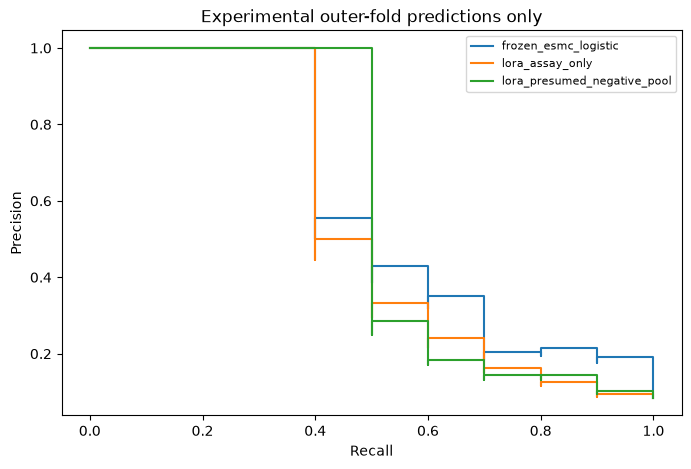

In [21]:
from sklearn.metrics import precision_recall_curve
fig, ax = plt.subplots(figsize=(8, 5))
for name, frame in PREDICTIONS[PREDICTIONS['split'].str.startswith('cv')].groupby('arm'):
    precision, recall, _ = precision_recall_curve(frame.label, frame.score)
    ax.step(recall, precision, where='post', label=name)
ax.set(xlabel='Recall', ylabel='Precision', title='Experimental outer-fold predictions only')
ax.legend(fontsize=8)
plt.show()

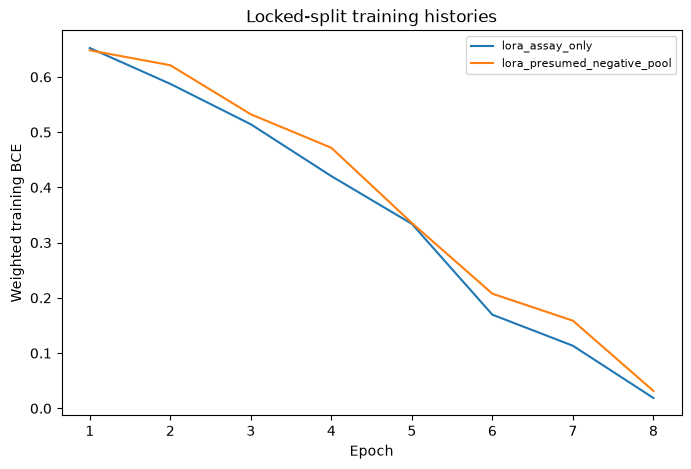

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, history in HISTORIES.items():
    h = pd.DataFrame(history)
    ax.plot(h.epoch, h.training_loss, label=name)
ax.set(xlabel='Epoch', ylabel='Weighted training BCE', title='Locked-split training histories')
ax.legend(fontsize=8)
plt.show()
# Different sampling/loss weighting means the two loss curves are not directly equivalent.

In [23]:
display(pd.DataFrame({k:{a:b for a,b in v.items() if a!='per_test_max_identity'}
                      for k,v in OVERLAP_AUDIT.items()}).T)
for result in RUN_SUMMARY['rows']:
    if 'gradient_checks' in result['locked_holdout']:
        print(result['arm'], result['locked_holdout']['gradient_checks'])

,max_train_identity,fraction_test_at_least_90pct,fraction_test_at_least_95pct
cv1,0.862500,0.0,0.0
cv2,0.850000,0.0,0.0
cv3,0.862500,0.0,0.0
locked_holdout,0.895522,0.0,0.0


lora_assay_only {'lora_nonzero_gradient': True, 'head_nonzero_gradient': True, 'frozen_parameter_unchanged': True, 'nonzero_lora_B_after_training': True}
lora_presumed_negative_pool {'lora_nonzero_gradient': True, 'head_nonzero_gradient': True, 'frozen_parameter_unchanged': True, 'nonzero_lora_B_after_training': True}


## Interpretation boundaries and next decision
A high random-split AP does not demonstrate generalization to a new scaffold. Inspect the overlap table, the tiny number of positives per test fold, and the assay-only baseline before deciding whether to put this model into a search loop. A generative search can exploit a classifier's errors.

The 0.1%-positive reservoir is a **training augmentation hypothesis**. Generated presumed negatives are neither measured TNF nonbinders nor proven binders of their donor targets. A favorable result would justify further evaluation, not validate the labels. The run does not predict human/mouse cross-reactivity, affinity, or pH dependence.

Adapters/checkpoints and sequence-level working data are kept locally; the PR publishes code, tutorial, aggregate results, and provenance, not a new biological hit claim.

### Sources
- [Anthropic binder dataset and assay documentation](https://huggingface.co/datasets/Anthropic/claude-protein-binder-design)
- [ESM implementation and ESMC models](https://github.com/biohub/esm)
- [PyTorch binary cross entropy with logits](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html)
- [PyTorch autograd tutorial](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html)
- [Scikit-learn average precision definition](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html)

All experimental claims in this notebook come from the source dataset or the accompanying completed Slurm artifacts.